In [7]:
import pandas as pd

data = pd.read_csv("round1data.csv")

In [8]:
print(f"Number of experimental runs: {data.shape[0]}")
print(f"Number of columns: {data.shape[1]}")

Number of experimental runs: 18
Number of columns: 12


In [19]:
data

,run_id,round,temperature_c,time_h,hto_mass_g,baoh_mass_g,water_initial_mL,water_rinse_mL,aspect_ratio,purity_pct,recipe_group,notes
0,RUN_001,1,210,12,0.1400,0.7716,50,10,14.285352,100,1,B1S1
1,RUN_002,1,210,12,0.1403,1.0253,50,10,14.108578,100,2,B1S2
2,RUN_003,1,210,12,0.1404,1.5434,50,10,12.863480,100,3,B1S3
3,RUN_004,1,210,12,0.1400,0.7717,50,10,15.454831,100,1,B2S1
4,RUN_005,1,210,12,0.1403,1.0253,50,10,15.654755,100,2,B2S2
5,RUN_006,1,210,12,0.1402,1.5429,50,10,14.458248,100,3,B2S3
6,RUN_007,1,210,6,0.1403,1.5425,50,10,13.082099,100,4,B3S1
7,RUN_008,1,210,6,0.1400,0.7712,55,10,13.013575,100,5,B3S2
8,RUN_009,1,210,6,0.1400,1.0248,55,10,11.550839,100,6,B3S3
9,RUN_010,1,210,24,0.1402,1.0253,40,10,13.198180,100,7,B4S1


In [10]:
data_check = pd.DataFrame({
    "data_type": data.dtypes,
    "missing_values": data.isna().sum(),
    "unique_values": data.nunique()
})

data_check

,data_type,missing_values,unique_values
run_id,str,0,18
round,int64,0,1
temperature_c,int64,0,1
time_h,int64,0,3
hto_mass_g,float64,0,6
baoh_mass_g,float64,0,13
water_initial_mL,int64,0,4
water_rinse_mL,int64,0,1
aspect_ratio (mean),float64,0,18
purity_pct,int64,0,1


In [11]:
summary_columns = [
    "temperature_c",
    "time_h",
    "hto_mass_g",
    "baoh_mass_g",
    "water_initial_mL",
    "water_rinse_mL",
    "aspect_ratio (mean)",
    "purity_pct"
]

# Calculate descriptive statistics for the selected columns
summary = data[summary_columns].describe().T

# Display the statistics to four decimal places
summary.round(4)

,count,mean,std,min,25%,50%,75%,max
temperature_c,18.0,210.0000,0.0000,210.0000,210.0000,210.0000,210.0000,210.0000
time_h,18.0,14.0000,7.7003,6.0000,6.0000,12.0000,24.0000,24.0000
hto_mass_g,18.0,0.1385,0.0072,0.1098,0.1400,0.1402,0.1403,0.1404
baoh_mass_g,18.0,1.1131,0.3303,0.7712,0.7716,1.0253,1.5426,1.5434
water_initial_mL,18.0,47.7778,7.7121,30.0000,50.0000,50.0000,50.0000,55.0000
water_rinse_mL,18.0,10.0000,0.0000,10.0000,10.0000,10.0000,10.0000,10.0000
aspect_ratio (mean),18.0,14.9305,3.0843,9.8157,13.0307,14.3718,16.4705,21.8210
purity_pct,18.0,100.0000,0.0000,100.0000,100.0000,100.0000,100.0000,100.0000


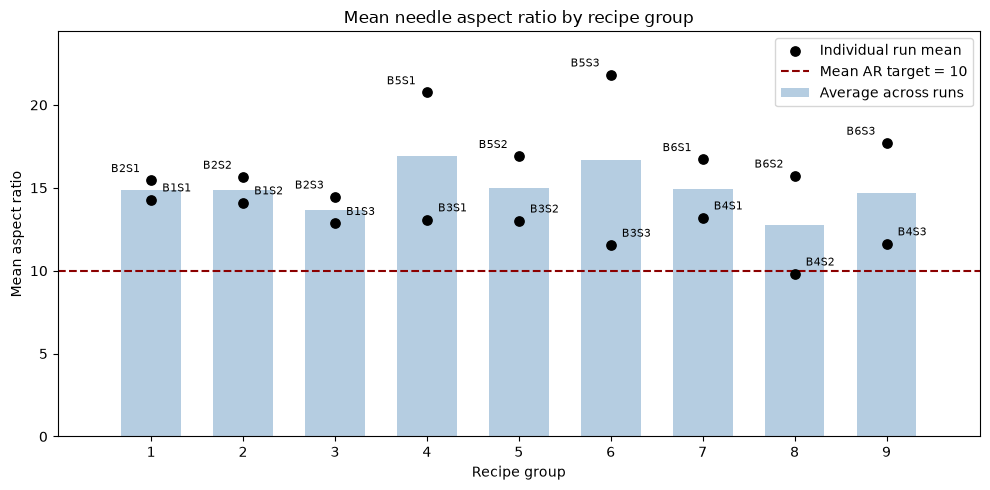

In [14]:
import matplotlib.pyplot as plt

data = data.rename(columns={
    "aspect_ratio (mean)": "aspect_ratio"
})

# Select valid measurements and arrange runs by recipe group
plot_data = (
    data.dropna(subset=["recipe_group", "aspect_ratio"])
    .sort_values(["recipe_group", "aspect_ratio"])
    .reset_index(drop=True)
)

# Calculate the average of the run means within each recipe group
group_mean = (
    plot_data.groupby("recipe_group")["aspect_ratio"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 5))

# Bars: average across runs
ax.bar(
    group_mean.index,
    group_mean.values,
    width=0.65,
    color="steelblue",
    alpha=0.4,
    label="Average across runs"
)

# Dots: individual run means
ax.scatter(
    plot_data["recipe_group"],
    plot_data["aspect_ratio"],
    color="black",
    s=45,
    zorder=3,
    label="Individual run mean"
)

# Label each dot using the notes column
for i, row in plot_data.iterrows():

    if pd.isna(row["notes"]):
        continue

    # Choose the label position for this particular point
    if i % 2 == 0:
        offset = 8
        alignment = "left"
    else:
        offset = -8
        alignment = "right"

    ax.annotate(
        text=str(row["notes"]),
        xy=(row["recipe_group"], row["aspect_ratio"]),
        xytext=(offset, 4),
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=8
    )

# Desired AR threshold
ax.axhline(
    y=10,
    color="darkred",
    linestyle="--",
    label="Mean AR target = 10"
)

ax.set_xticks(group_mean.index)

ax.set_xlabel("Recipe group")
ax.set_ylabel("Mean aspect ratio")
ax.set_title("Mean needle aspect ratio by recipe group")

# Leave room for labels while keeping the bar-chart baseline at zero
ax.margins(x=0.08, y=0.12)
ax.set_ylim(bottom=0)

ax.legend()
fig.tight_layout()

plt.show()

This plot shows the relationship between the two observations with the same recipe. 

1) We can see that across all the recipe groups, the observations from the 2nd experiment using the same recipe gave a higher mean AR. 
    - B2 is higher than B1.
    - B5 is higher than B3.
    - B6 is higher than B4.

    Possible explanations include preparation, processing, SEM sampling, or measurement procedures; the chart cannot identify the cause.

2) Recipe groups 4 and 6 have the highest mean recipe AR. However, the two observations within the same recipe group differ significantly. 
    This is with comparison with recipe groups 1, 2, 3, where the observations with the same recipe group are quite close to each other. 
        - We cannot confidently conclude that batch 4 or 6 has the best recipe since the results are not consistent based on the two runs. 

3) Recipe group 8 has a run that is below the required AR >= 10. 

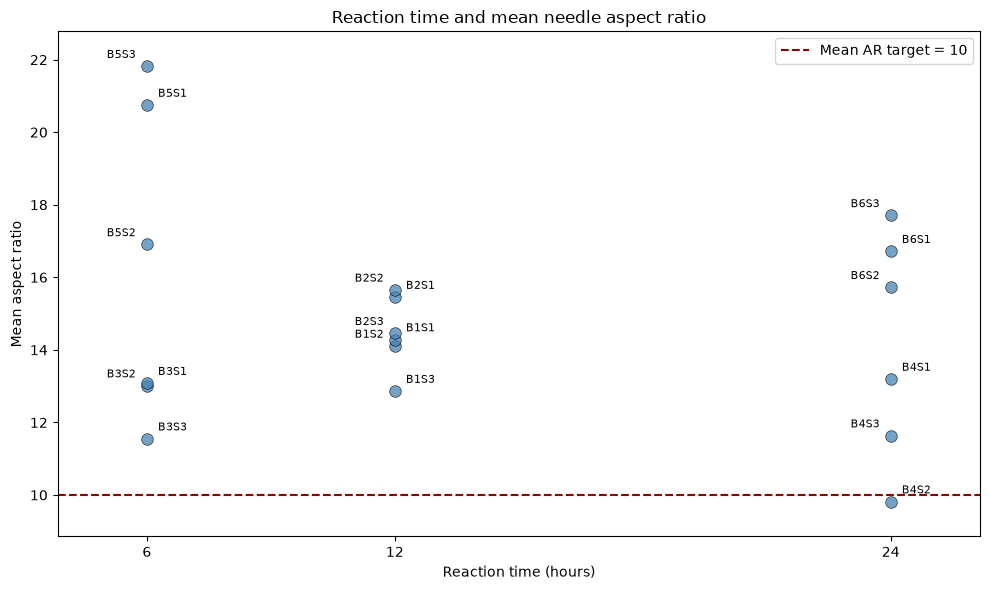

In [15]:
scatter_data = (
    data.dropna(subset=["time_h", "aspect_ratio"])
    .sort_values(["time_h", "aspect_ratio"])
    .reset_index(drop=True)
)

# Use a slightly larger figure to give labels more space
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the measurements
ax.scatter(
    scatter_data["time_h"],
    scatter_data["aspect_ratio"],
    color="steelblue",
    s=70,
    alpha=0.75,
    edgecolors="black",
    linewidths=0.5
)

# Add the text from the notes column beside each point
for i, row in scatter_data.iterrows():

    # Leave the point unlabelled if its note is missing
    if pd.isna(row["notes"]):
        continue

    # Alternate labels between the right and left
    if i % 2 == 0:
        offset = 8
        alignment = "left"
    else:
        offset = -8
        alignment = "right"

    ax.annotate(
        text=str(row["notes"]),
        xy=(row["time_h"], row["aspect_ratio"]),
        xytext=(offset, 4),
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=8
    )

# Add the desired AR threshold
ax.axhline(
    y=10,
    color="darkred",
    linestyle="--",
    label="Mean AR target = 10"
)

ax.set_xticks(sorted(scatter_data["time_h"].unique()))

ax.set_xlabel("Reaction time (hours)")
ax.set_ylabel("Mean aspect ratio")
ax.set_title("Reaction time and mean needle aspect ratio")

# Add space around the outermost points for their labels
ax.margins(x=0.12, y=0.08)

ax.legend()
fig.tight_layout()

plt.show()

This plot shows the relationship between the reaction run time and mean AR. 

6h - observed range is 11.55–21.82 (Contains the highest results but have a wide spread)

12h - observed range is 12.86–15.65 (Results are more closely clustered)

24h - observed range is 9.82–17.71 (Similar wide spread as the 6h, but have lower results in general, with one below the required AR >= 10)

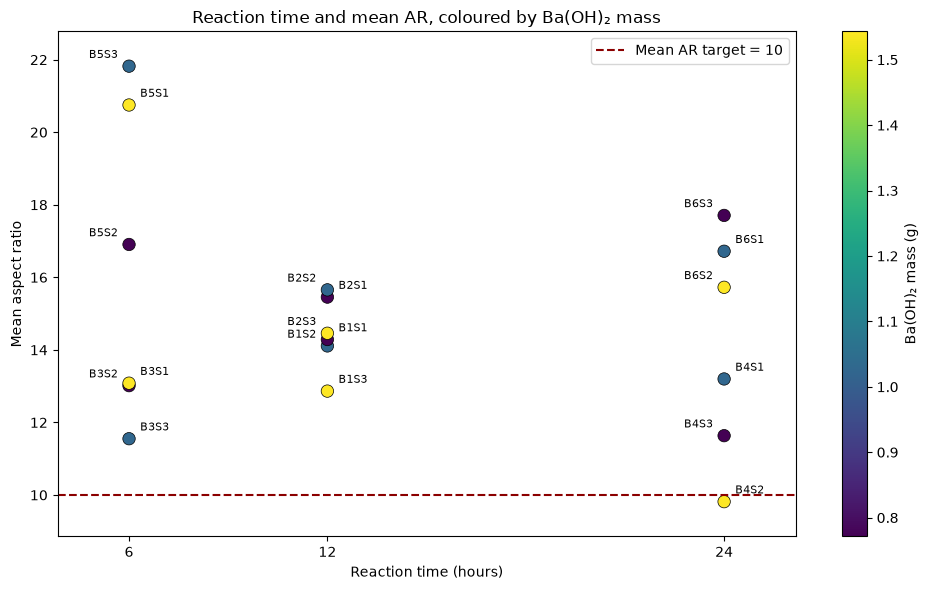

In [16]:
# Explore reaction time, BaOH mass, and mean AR together

# Select complete measurements and arrange nearby points together
scatter_data = (
    data.dropna(subset=["time_h", "baoh_mass_g", "aspect_ratio"])
    .sort_values(["time_h", "aspect_ratio"])
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

# Colour each point according to its BaOH mass
points = ax.scatter(
    scatter_data["time_h"],
    scatter_data["aspect_ratio"],
    c=scatter_data["baoh_mass_g"],
    cmap="viridis",
    s=80,
    edgecolors="black",
    linewidths=0.5
)

# Add a colour scale showing what the colours represent
colourbar = fig.colorbar(points, ax=ax)
colourbar.set_label("Ba(OH)₂ mass (g)")

# Label each point using the notes column
for i, row in scatter_data.iterrows():

    if pd.isna(row["notes"]):
        continue

    if i % 2 == 0:
        offset = 8
        alignment = "left"
    else:
        offset = -8
        alignment = "right"

    ax.annotate(
        text=str(row["notes"]),
        xy=(row["time_h"], row["aspect_ratio"]),
        xytext=(offset, 4),
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=8
    )

# Desired AR threshold
ax.axhline(
    y=10,
    color="darkred",
    linestyle="--",
    label="Mean AR target = 10"
)

ax.set_xticks(sorted(scatter_data["time_h"].unique()))

ax.set_xlabel("Reaction time (hours)")
ax.set_ylabel("Mean aspect ratio")
ax.set_title("Reaction time and mean AR, coloured by Ba(OH)₂ mass")

ax.margins(x=0.12, y=0.08)
ax.legend()

fig.tight_layout()
plt.show()

The positions of the dots are unchanged from the previous plot. Their colours now provide additional information:
- Purple: approximately 0.77 g BaOH.
- Teal: approximately 1.03 g.
- Yellow: approximately 1.54 g.

The plot provides no consistent evidence that “more BaOH gives higher AR”.

That does not establish that BaOH is irrelevant. Its effect could depend on other processing conditions, and the variation between experiments may make its relationship with AR difficult to identify.

Runs included in the heatmap: 18


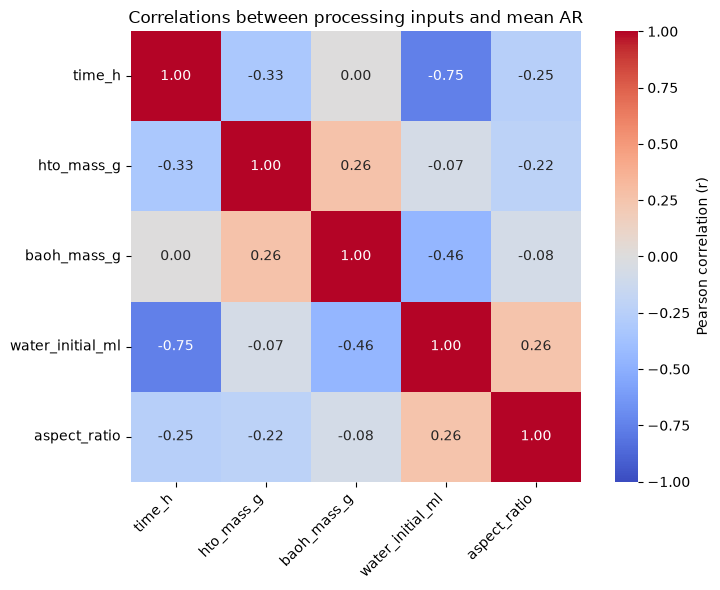

In [ ]:
# Correlation heatmap

import seaborn as sns

# Keep the water-volume column name consistent
data = data.rename(columns={
    "water_initial_mL": "water_initial_ml"
})

# Select varying processing inputs and the measured outcome
correlation_columns = [
    "time_h",
    "hto_mass_g",
    "baoh_mass_g",
    "water_initial_ml",
    "aspect_ratio"
]

# Use runs with complete values for these columns
correlation_data = data[correlation_columns].dropna()

print(f"Runs included in the heatmap: {len(correlation_data)}")

# Calculate the correlation between every pair of selected variables
correlation = correlation_data.corr(method="pearson")

# Draw the heatmap
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={"label": "Pearson correlation (r)"},
    ax=ax
)

ax.set_title("Correlations between processing inputs and mean AR")

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)

fig.tight_layout()
plt.show()
This heatmap shows the correlation of each variable to the AR. 

Correlation with mean AR:
    1) Reaction time | −0.25 |
    2) HTO mass | −0.22 |
    3) BaOH mass | −0.08 |
    4) Initial water volume | +0.26 |

None shows a strong linear association with AR. However, a weak correlation does not rule out a nonlinear relationship or an effect that depends on another variable.


It is interesting to note that strong relationship between reaction time and inital water volume (-0.75). 
In our experiments:
- The 6-hour runs used 50–55 mL.
- The 12-hour runs used 50 mL.
- The 24-hour runs used 30–50 mL.

This heatmap suggests that longer reaction times were often accompanied by lower water volumes. 

However, this time-related pattern could partly reflect the accompanying water-volume change.

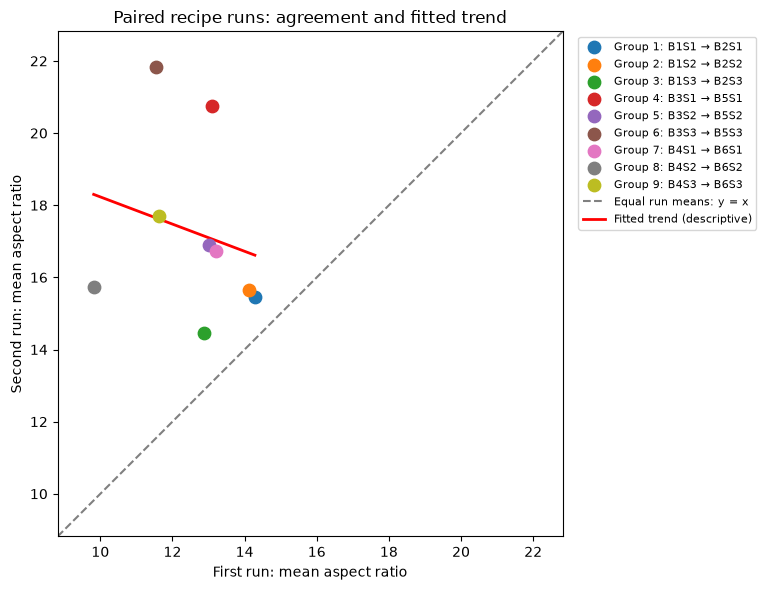

In [22]:
# Paired-run agreement with a fitted trend line

import numpy as np
import matplotlib.pyplot as plt

# Order runs by recipe group and run ID, not by AR
paired_data = (
    data.dropna(subset=["recipe_group", "aspect_ratio"])
    .sort_values(["recipe_group", "run_id"])
    .copy()
)

# Require two measured runs per group
group_counts = paired_data.groupby("recipe_group").size()

if not group_counts.eq(2).all():
    raise ValueError(
        "This plot requires exactly two measured runs per recipe group."
    )

# Collect the paired results and sample labels
paired = paired_data.groupby("recipe_group").agg(
    first_ar=("aspect_ratio", "first"),
    second_ar=("aspect_ratio", "last"),
    first_sample=("notes", "first"),
    second_sample=("notes", "last")
)

# Extract the horizontal and vertical values
x = paired["first_ar"].to_numpy()
y = paired["second_ar"].to_numpy()

# Fit a straight line: y = slope*x + intercept
slope, intercept = np.polyfit(x, y, deg=1)

# Draw the fit only over the observed first-run AR range
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(figsize=(11, 6))

# Plot each recipe pair
for group, row in paired.iterrows():

    ax.scatter(
        row["first_ar"],
        row["second_ar"],
        s=80,
        zorder=3,
        label=(
            f"Group {group}: "
            f"{row['first_sample']} → {row['second_sample']}"
        )
    )

# Shared limits for both axes
lower = paired_data["aspect_ratio"].min() - 1
upper = paired_data["aspect_ratio"].max() + 1

# Grey diagonal: identical results in both runs
ax.plot(
    [lower, upper],
    [lower, upper],
    color="grey",
    linestyle="--",
    label="Equal run means: y = x"
)

# Red line: fitted relationship between paired results
ax.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Fitted trend (descriptive)"
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("First run: mean aspect ratio")
ax.set_ylabel("Second run: mean aspect ratio")
ax.set_title("Paired recipe runs: agreement and fitted trend")

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8
)

fig.tight_layout()
plt.show()

This plot shows the relationship between the two runs in each recipe group respectively. 

    - Every point lies above the grey diagonal. Therefore, the second run has a higher mean AR in all nine recipe pairs.
    - Groups 1–3 are relatively close to the equality line. Groups 4 and 6 show much larger differences.

The red line shows a slightly downwards slope, with the points scattered widely around it. 
    - This is not a useful straight-line relationship between the first and second runs.

The grey dotted line is the main important reference to look at because it shows how much the results of the first and second run agrees with each other. 

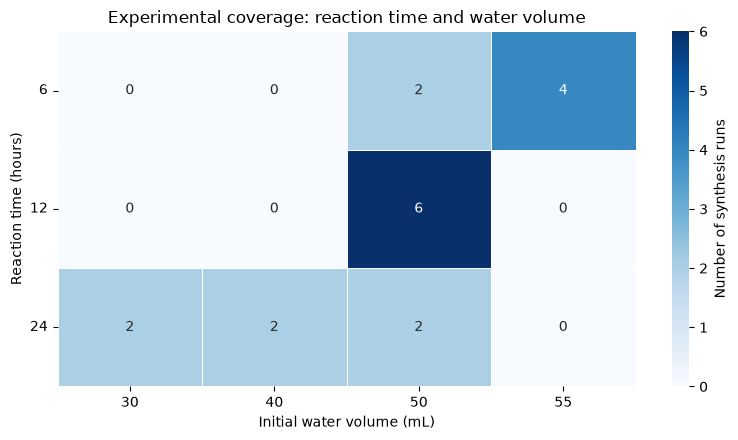

In [23]:
# Relationship of reaction time and initial water volume, since we saw a strong negative correlation between them in the heatmap.

# Keep the water-volume column name consistent
data = data.rename(columns={
    "water_initial_mL": "water_initial_ml"
})

# Count runs at each combination of time and water volume
coverage = pd.crosstab(
    index=data["time_h"],
    columns=data["water_initial_ml"]
)

# Create the figure
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.heatmap(
    coverage,
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    linewidths=0.5,
    cbar_kws={"label": "Number of synthesis runs"},
    ax=ax
)

ax.set_xlabel("Initial water volume (mL)")
ax.set_ylabel("Reaction time (hours)")
ax.set_title("Experimental coverage: reaction time and water volume")

# Keep the reaction-time labels horizontal
plt.setp(ax.get_yticklabels(), rotation=0)

fig.tight_layout()
plt.show()

From this plot, we can observe that:

Shorter reactions used relatively high water volumes, while the lower volumes were tested only at 24 hours. This helps explain the strong negative correlation between time and water volume in the earlier heatmap.

So, the strong correlation could be due to the processing conditions used for each experiment, it does not establish a concrete evidence that longer reaction time requires less initial water volume. 

In [24]:
# Processing variables used to predict mean aspect ratio
feature_columns = [
    "time_h",
    "hto_mass_g",
    "baoh_mass_g",
    "water_initial_ml"
]

# X contains the model inputs: one row per synthesis run
X = data[feature_columns].copy()

# y contains the measured mean aspect ratio for each run
y = data["aspect_ratio"].copy()

# Recipe groups will control how observations are split
groups = data["recipe_group"].copy()

# Check the size of the modelling dataset
print("Number of experiments:", len(X))
print("Number of input features:", X.shape[1])
print("Number of target values:", len(y))
print("Number of recipe groups:", groups.nunique())

# Preview the input table
display(X.head())

Number of experiments: 18
Number of input features: 4
Number of target values: 18
Number of recipe groups: 9


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml
0,12,0.1400,0.7716,50
1,12,0.1403,1.0253,50
2,12,0.1404,1.5434,50
3,12,0.1400,0.7717,50
4,12,0.1403,1.0253,50


In [25]:
# Create shared grouped cross-validation splits

from sklearn.model_selection import GroupKFold

# Divide the recipe groups into three folds
cv = GroupKFold(n_splits=3)

# Create the splits once.
# Every model will reuse this exact list.
cv_splits = list(cv.split(X, y, groups))

# Collect information about each fold
fold_rows = []

for fold, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    # Identify the recipe groups assigned to each portion
    train_groups = sorted(groups.iloc[train_idx].unique())
    test_groups = sorted(groups.iloc[test_idx].unique())

    # Record the assignments and number of runs
    fold_rows.append({
        "Fold": fold,
        "Training recipe groups": train_groups,
        "Held-out recipe groups": test_groups,
        "Training runs": len(train_idx),
        "Held-out runs": len(test_idx)
    })

# Display the split arrangements as a table
fold_summary = pd.DataFrame(fold_rows)

display(fold_summary)

,Fold,Training recipe groups,Held-out recipe groups,Training runs,Held-out runs
0,1,"[1, 2, 4, 5, 7, 8]","[3, 6, 9]",12,6
1,2,"[1, 3, 4, 6, 7, 9]","[2, 5, 8]",12,6
2,3,"[2, 3, 5, 6, 8, 9]","[1, 4, 7]",12,6


The above cell helps to split the dataset into 3 different fold, each having different recipe groups in the training and held-out columns respectively. 

Each fold gets a fresh model with the same hyperparameter settings. Keeping the settings consistent lets us assess how the same modelling configuration performs across different data splits.
    - The learned information can differ between each fold even though the same configuration was used
    - RF-A might learn a useful split based on reaction time, while RF-B might learn a different split because its training observations differ.
    - Nothing learned by RF-A carries into RF-B or RF-C.

For example:
| Candidate setting | Inner Fold 1 MAE | Inner Fold 2 MAE | Inner Fold 3 MAE | Average validation MAE |
|---|---:|---:|---:|---:|
| `max_depth = 2` | 2.8 | 2.4 | 3.2 | 2.8 |
| `max_depth = 4` | 2.1 | 2.6 | 2.2 | **2.3** |
| `max_depth = 6` | 2.0 | 2.9 | 2.6 | 2.5 |


The hyperparameter settings for each model to be evaluated will be defined in the following cells.





In [26]:
# Prepare inner grouped folds for hyperparameter tuning

# Use three inner folds within each outer-training subset
inner_cv = GroupKFold(n_splits=3)

# Store the inner splits for each outer fold.
# These will be reused across candidate settings and models.
inner_cv_splits = []

# Store information for a readable summary table
inner_fold_rows = []

# Work through the outer splits created in Cell 11
for outer_fold, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    # Select only this outer fold's training observations
    X_outer_train = X.iloc[train_idx]
    y_outer_train = y.iloc[train_idx]
    groups_outer_train = groups.iloc[train_idx]

    # Create inner splits using only those training observations
    current_inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups_outer_train
        )
    )

    # Save this outer fold's inner splits
    inner_cv_splits.append(current_inner_splits)

    # Record the recipe groups and run counts for each inner split
    for inner_fold, (fit_idx, val_idx) in enumerate(
        current_inner_splits,
        start=1
    ):

        inner_fold_rows.append({
            "Outer fold": outer_fold,
            "Inner fold": inner_fold,
            "Training groups": sorted(
                groups_outer_train.iloc[fit_idx].unique()
            ),
            "Validation groups": sorted(
                groups_outer_train.iloc[val_idx].unique()
            ),
            "Training runs": len(fit_idx),
            "Validation runs": len(val_idx)
        })

# Display all inner-fold arrangements
inner_fold_summary = pd.DataFrame(inner_fold_rows)

display(inner_fold_summary)

,Outer fold,Inner fold,Training groups,Validation groups,Training runs,Validation runs
0,1,1,"[1, 2, 5, 7]","[4, 8]",8,4
1,1,2,"[1, 4, 5, 8]","[2, 7]",8,4
2,1,3,"[2, 4, 7, 8]","[1, 5]",8,4
3,2,1,"[1, 3, 6, 7]","[4, 9]",8,4
4,2,2,"[1, 4, 6, 9]","[3, 7]",8,4
5,2,3,"[3, 4, 7, 9]","[1, 6]",8,4
6,3,1,"[2, 3, 6, 8]","[5, 9]",8,4
7,3,2,"[2, 5, 6, 9]","[3, 8]",8,4
8,3,3,"[3, 5, 8, 9]","[2, 6]",8,4


This cell defines which observations tuning can use. It does not fit models or select settings yet.

During tuning, each candidate will be fitted and validated across these inner splits. The selected configuration will then be fitted on all 12 outer-training runs and evaluated on the six outer-held-out runs.

In [27]:
# Evaluate the mean baseline using grouped cross-validation

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create one empty prediction position for each experiment.
# These positions will be filled when each run is held out.
baseline_oof_predictions = np.full(len(y), np.nan)

# Store the results from each outer fold
baseline_fold_rows = []

for fold, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    # Select this fold's training and held-out observations
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Create a fresh baseline for this fold
    baseline = DummyRegressor(strategy="mean")

    # Learn the average AR using only the training outcomes
    baseline.fit(X_train, y_train)

    # Predict the held-out outcomes
    predictions = baseline.predict(X_test)

    # Save predictions in their original row positions
    baseline_oof_predictions[test_idx] = predictions

    # Calculate and record this fold's prediction errors
    baseline_fold_rows.append({
        "Fold": fold,
        "Baseline prediction": float(y_train.mean()),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

# Create the table of individual fold results
baseline_fold_results = pd.DataFrame(baseline_fold_rows)

# Calculate overall errors from all 18 out-of-fold predictions
baseline_results = pd.DataFrame([{
    "Model": "Mean baseline",
    "OOF MAE": mean_absolute_error(y, baseline_oof_predictions),
    "OOF RMSE": np.sqrt(
        mean_squared_error(y, baseline_oof_predictions)
    )
}])

# Display both summaries
display(baseline_fold_results.round(4))
display(baseline_results.round(4))

,Fold,Baseline prediction,MAE,RMSE
0,1,14.8928,3.1343,3.6970
1,2,15.2937,1.8913,2.5667
2,3,14.6049,2.0598,2.8095


,Model,OOF MAE,OOF RMSE
0,Mean baseline,2.3618,3.0632


For each fold, it will:

    1. Calculate the average AR of the 12 training runs.
    2. Predict that average for each of the six held-out runs.
    3. Compare those predictions with the measured values.
    4. Save the predictions and errors.

The baseline has no settings to search, so it does not use the inner folds.


Lower MAE is better; zero means perfect predictions.
RMSE places more emphasis on large errors. Similarly, lower RMSE is better. 

An MAE of 2.3618 means the baseline’s held-out predictions differ from the measured run means by approximately 2.36 AR units on average.

These are the benchmark errors we will compare with the tuned RF, Matérn GP and RBF GP.

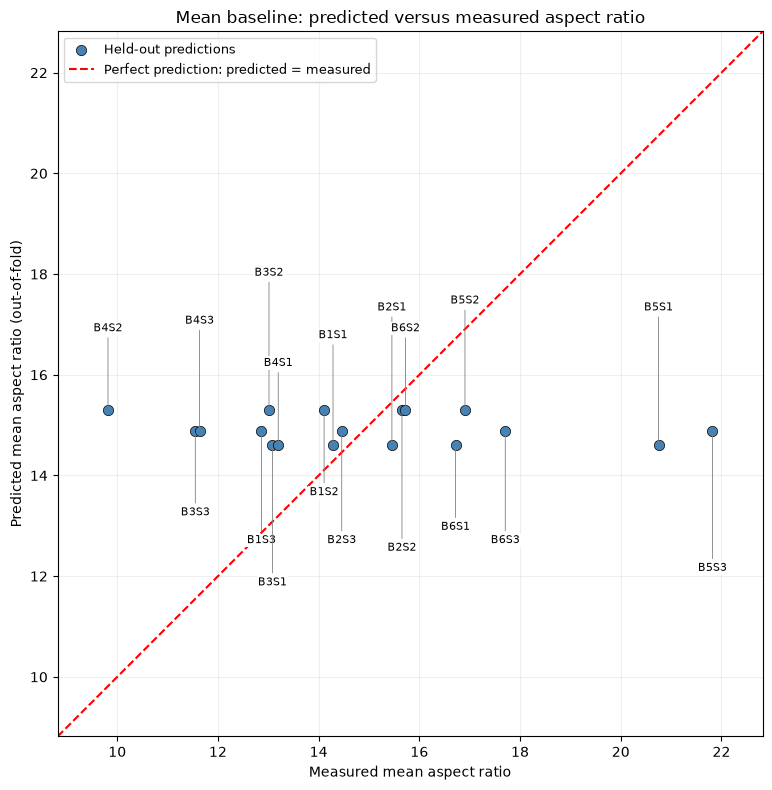

In [28]:
# Plot baseline predictions against measured mean AR

import pandas as pd
import matplotlib.pyplot as plt

# Match each measured value with its held-out prediction and sample label
baseline_plot_data = pd.DataFrame({
    "measured_ar": y.to_numpy(),
    "predicted_ar": baseline_oof_predictions,
    "notes": data.loc[y.index, "notes"].to_numpy()
})

# Sort for consistent placement of the text labels
baseline_plot_data = (
    baseline_plot_data
    .sort_values("measured_ar")
    .reset_index(drop=True)
)

# Use the same limits for both axes
lower = min(
    baseline_plot_data["measured_ar"].min(),
    baseline_plot_data["predicted_ar"].min()
) - 1

upper = max(
    baseline_plot_data["measured_ar"].max(),
    baseline_plot_data["predicted_ar"].max()
) + 1

fig, ax = plt.subplots(figsize=(8, 8))

# Each dot represents one held-out prediction
ax.scatter(
    baseline_plot_data["measured_ar"],
    baseline_plot_data["predicted_ar"],
    color="steelblue",
    edgecolors="black",
    linewidths=0.5,
    s=55,
    zorder=3,
    label="Held-out predictions"
)

# Perfect prediction occurs when predicted AR equals measured AR
ax.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Perfect prediction: predicted = measured"
)

# Stagger labels above and below the points to reduce overlap
label_offsets = [55, -55, 75, -75, 95, -95]

for i, row in baseline_plot_data.iterrows():

    if pd.isna(row["notes"]) or str(row["notes"]).strip() == "":
        continue

    offset = label_offsets[i % len(label_offsets)]

    ax.annotate(
        str(row["notes"]),
        xy=(row["measured_ar"], row["predicted_ar"]),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        va="bottom" if offset > 0 else "top",
        fontsize=8,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "pad": 0.8
        },
        arrowprops={
            "arrowstyle": "-",
            "color": "gray",
            "lw": 0.6
        }
    )

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Measured mean aspect ratio")
ax.set_ylabel("Predicted mean aspect ratio (out-of-fold)")
ax.set_title("Mean baseline: predicted versus measured aspect ratio")

ax.grid(alpha=0.2)
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

This plot is obtained using the prediction results from the previous cell. 

Every point represents a run that was withheld when its prediction was generated.

We can observe that the scattered points form an almost horizontal trend line. 
    - This is because the baseline predicts a training average for every withheld run, so there are only three possible prediction heights.
    - This shows the baseline’s limitation: it cannot adapt its prediction to a recipe that produces particularly low or high AR. Its predictions tend to be too high for low-AR samples and too low for high-AR samples.

Next few cells will assess whether the tuned RF and GP models can predict these differences more accurately.

In [40]:
# Define the Random Forest Regressor and its hyperparameter candidates

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

# Primary metric used to select hyperparameters.
# We will use the same selection metric for RF and the GP models.
selection_scoring = "neg_root_mean_squared_error"

# Settings that remain fixed across the candidate configurations
rf_model = RandomForestRegressor(
    n_estimators=200,
    criterion="squared_error",
    bootstrap=True,
    random_state=42,
    n_jobs=1
)

# Hyperparameter values that inner cross-validation will compare
rf_param_grid = {
    "max_depth": [1, 2, 3, None],
    "min_samples_leaf": [1, 2, 3],
    "max_features": [0.5, 1.0]
}

# Expand the grid into a table showing every candidate combination
rf_candidates = pd.DataFrame(
    list(ParameterGrid(rf_param_grid)),
    dtype=object
)

# Number the candidates from 1 for easier reading
rf_candidates.index = rf_candidates.index + 1
rf_candidates.index.name = "Candidate"

print("Number of RF configurations:", len(rf_candidates))

display(rf_candidates)

Number of RF configurations: 24


,max_depth,max_features,min_samples_leaf
Candidate,,,
1,1,0.5,1
2,1,0.5,2
3,1,0.5,3
4,1,1.0,1
5,1,1.0,2
6,1,1.0,3
7,2,0.5,1
8,2,0.5,2
9,2,0.5,3


The fixed outer fold settings are:

    1) n_estimators - control tree complexity. Averaging more trees can reduce randomness in the forest’s predictions, but it does not create additional experimental information.
    2) criterion="squared_error" - Trees choose splits that reduce squared prediction error within their training observations.
    3) bootstrap=True - Each tree receives a sample drawn with replacement from the available training rows. Some rows can appear repeatedly.
    4) random_state=42 - ensures reproducibility
    5) n_jobs=1

The tunable inner fold settings are:

    1) max_depth: how complicated can each tree become?
            - 1: at most one split, producing at most two leaves.
            - 2: permits another split level, producing at most four leaves.
            - None: removes the explicit depth limit; the other stopping rules still apply.
            A shallow tree may miss useful relationships. A very flexible tree may follow variation that does not generalise to other experiments.

            Because each inner fit has only eight runs, we include very shallow options. Inner validation will determine which tested configuration predicts its withheld runs best.

    2) min_samples_leaf: how much data supports a terminal prediction?

            A leaf is the final region reached after following a tree’s split rules.

            With our squared-error criterion, its prediction is an average of the training outcomes assigned to it.

            Allowing a leaf supported by one observation gives the tree more flexibility. Requiring at least two restricts that flexibility. With this small dataset, that restriction can make a substantial difference.

    3) max_features: how many inputs can compete at a split?

            We have four input features:
            - Reaction time.
            - HTO mass.
            - Ba(OH)₂ mass.
            - Initial water volume.
            0.5 normally considers a randomly selected pair of these inputs at each split; 1.0 considers all four.

            This does not permanently remove columns from the model. Different splits can consider different features.

In [41]:
# Tune and evaluate Random Forest using nested grouped CV

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Store one held-out prediction for each experiment
rf_oof_predictions = np.full(len(y), np.nan)

# Store the summary from each outer fold
rf_fold_rows = []

# Keep each fitted search for later inspection and visualisation
rf_searches = []

for fold, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    print(
        f"Running RF search for outer fold "
        f"{fold} of {len(cv_splits)}..."
    )

    # Select the matching outer-training and held-out observations
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Compare candidate configurations using only inner validation
    search = GridSearchCV(
        estimator=rf_model,
        param_grid=rf_param_grid,
        scoring=selection_scoring,
        cv=inner_cv_splits[fold - 1],
        refit=True,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise"
    )

    # Run the inner search, then refit the selected configuration
    # on all observations supplied here: the 12 outer-training runs
    search.fit(X_train, y_train)

    # Predict the six outer-held-out runs
    predictions = search.predict(X_test)

    # Save predictions in their original row positions
    rf_oof_predictions[test_idx] = predictions

    # Save the search results and its refitted winning model
    rf_searches.append(search)

    # Record the selected settings and prediction errors
    rf_fold_rows.append({
        "Fold": fold,
        "max_depth": str(search.best_params_["max_depth"]),
        "min_samples_leaf": search.best_params_["min_samples_leaf"],
        "max_features": search.best_params_["max_features"],
        "Inner CV RMSE": -search.best_score_,
        "Held-out MAE": mean_absolute_error(y_test, predictions),
        "Held-out RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        )
    })

# Summarise the three outer folds
rf_fold_results = pd.DataFrame(rf_fold_rows)

# Calculate overall errors from all 18 held-out predictions
rf_results = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "OOF MAE": mean_absolute_error(y, rf_oof_predictions),
    "OOF RMSE": np.sqrt(
        mean_squared_error(y, rf_oof_predictions)
    )
}])

# Compare RF with the baseline using the same evaluation observations
model_comparison = pd.concat(
    [baseline_results, rf_results],
    ignore_index=True
)

display(rf_fold_results.round(4))
display(model_comparison.round(4))

Running RF search for outer fold 1 of 3...
Running RF search for outer fold 2 of 3...
Running RF search for outer fold 3 of 3...


,Fold,max_depth,min_samples_leaf,max_features,Inner CV RMSE,Held-out MAE,Held-out RMSE
0,1,1,3,0.5,2.2834,3.1538,3.6365
1,2,1,3,0.5,3.3804,1.8913,2.5870
2,3,None,1,0.5,3.1007,2.3503,3.0203


,Model,OOF MAE,OOF RMSE
0,Mean baseline,2.3618,3.0632
1,Tuned Random Forest,2.4651,3.1112


What GridSearchCV does

It automates the candidate comparison we defined in the previous cell for the tunable hyperparameters:

12 configuration x 3 inner folds = 36 candidate fits

This automation is only within the range defined!!! It does not search every possible hyperparameter values!

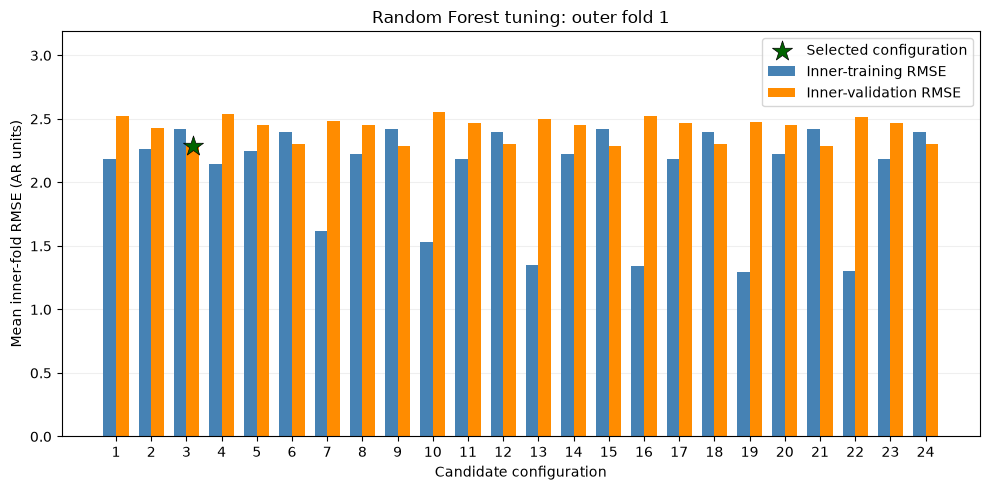

Selected candidate: 3
Selected settings: {'max_depth': 1, 'max_features': 0.5, 'min_samples_leaf': 3}


,Candidate,max_depth,max_features,min_samples_leaf,Training RMSE,Validation RMSE
0,1,1,0.5,1,2.1816,2.5238
1,2,1,0.5,2,2.2651,2.4287
2,3,1,0.5,3,2.4218,2.2834
3,4,1,1.0,1,2.1475,2.5378
4,5,1,1.0,2,2.2441,2.4544
5,6,1,1.0,3,2.3990,2.2995
6,7,2,0.5,1,1.6200,2.4863
7,8,2,0.5,2,2.2216,2.4490
8,9,2,0.5,3,2.4218,2.2834
9,10,2,1.0,1,1.5281,2.5514


In [42]:
# Visualise RF training and validation errors during tuning

# Choose which completed outer-fold search to inspect: 1, 2 or 3
outer_fold_to_plot = 1

# Retrieve its saved search results
plot_search = rf_searches[outer_fold_to_plot - 1]
search_results = pd.DataFrame(plot_search.cv_results_)

# Create a table linking candidate numbers to their hyperparameters
rf_tuning_table = pd.DataFrame(
    search_results["params"].tolist(),
    dtype=object
)

candidate_numbers = np.arange(1, len(rf_tuning_table) + 1)
rf_tuning_table.insert(0, "Candidate", candidate_numbers)

# Convert negative scores back into positive RMSE values
rf_tuning_table["Training RMSE"] = (
    -search_results["mean_train_score"]
)

rf_tuning_table["Validation RMSE"] = (
    -search_results["mean_test_score"]
)

# Convert the selected candidate's zero-based index into its table number
selected_candidate = plot_search.best_index_ + 1

# Plot training and validation errors beside each other
bar_width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    candidate_numbers - bar_width / 2,
    rf_tuning_table["Training RMSE"],
    width=bar_width,
    color="steelblue",
    label="Inner-training RMSE"
)

ax.bar(
    candidate_numbers + bar_width / 2,
    rf_tuning_table["Validation RMSE"],
    width=bar_width,
    color="darkorange",
    label="Inner-validation RMSE"
)

# Mark the configuration selected by GridSearchCV
ax.scatter(
    selected_candidate + bar_width / 2,
    -plot_search.best_score_,
    marker="*",
    s=230,
    color="darkgreen",
    edgecolors="black",
    linewidths=0.5,
    zorder=5,
    label="Selected configuration"
)

ax.set_xticks(candidate_numbers)
ax.set_xlabel("Candidate configuration")
ax.set_ylabel("Mean inner-fold RMSE (AR units)")
ax.set_title(
    f"Random Forest tuning: outer fold {outer_fold_to_plot}"
)

# Leave space above the bars for the legend
ax.set_ylim(
    0,
    max(
        rf_tuning_table["Training RMSE"].max(),
        rf_tuning_table["Validation RMSE"].max()
    ) * 1.25
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

print("Selected candidate:", selected_candidate)
print("Selected settings:", plot_search.best_params_)

display(rf_tuning_table.round(4))

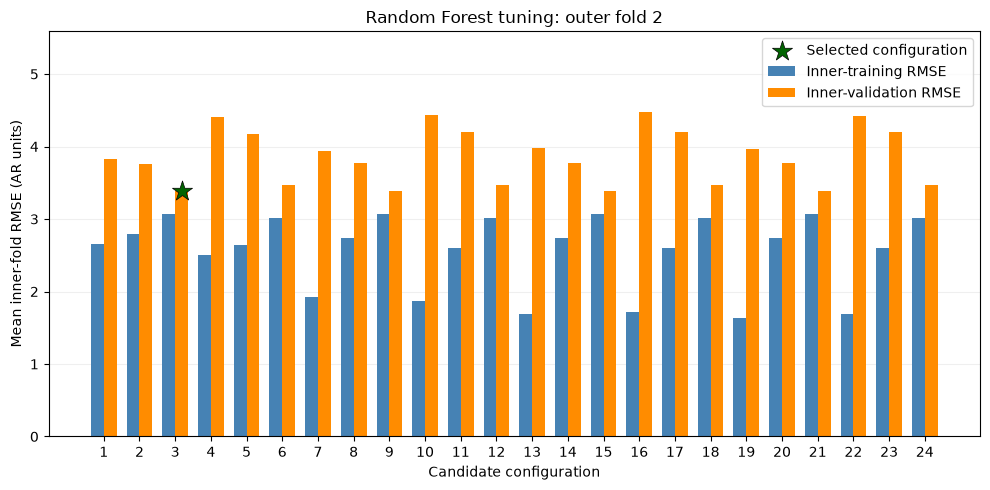

Selected candidate: 3
Selected settings: {'max_depth': 1, 'max_features': 0.5, 'min_samples_leaf': 3}


,Candidate,max_depth,max_features,min_samples_leaf,Training RMSE,Validation RMSE
0,1,1,0.5,1,2.6509,3.8332
1,2,1,0.5,2,2.7870,3.7601
2,3,1,0.5,3,3.0701,3.3804
3,4,1,1.0,1,2.4973,4.4017
4,5,1,1.0,2,2.6464,4.1754
5,6,1,1.0,3,3.0081,3.4761
6,7,2,0.5,1,1.9231,3.9383
7,8,2,0.5,2,2.7395,3.7766
8,9,2,0.5,3,3.0701,3.3804
9,10,2,1.0,1,1.8748,4.4363


In [43]:
# Visualise RF training and validation errors during tuning

# Choose which completed outer-fold search to inspect: 1, 2 or 3
outer_fold_to_plot = 2

# Retrieve its saved search results
plot_search = rf_searches[outer_fold_to_plot - 1]
search_results = pd.DataFrame(plot_search.cv_results_)

# Create a table linking candidate numbers to their hyperparameters
rf_tuning_table = pd.DataFrame(
    search_results["params"].tolist(),
    dtype=object
)

candidate_numbers = np.arange(1, len(rf_tuning_table) + 1)
rf_tuning_table.insert(0, "Candidate", candidate_numbers)

# Convert negative scores back into positive RMSE values
rf_tuning_table["Training RMSE"] = (
    -search_results["mean_train_score"]
)

rf_tuning_table["Validation RMSE"] = (
    -search_results["mean_test_score"]
)

# Convert the selected candidate's zero-based index into its table number
selected_candidate = plot_search.best_index_ + 1

# Plot training and validation errors beside each other
bar_width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    candidate_numbers - bar_width / 2,
    rf_tuning_table["Training RMSE"],
    width=bar_width,
    color="steelblue",
    label="Inner-training RMSE"
)

ax.bar(
    candidate_numbers + bar_width / 2,
    rf_tuning_table["Validation RMSE"],
    width=bar_width,
    color="darkorange",
    label="Inner-validation RMSE"
)

# Mark the configuration selected by GridSearchCV
ax.scatter(
    selected_candidate + bar_width / 2,
    -plot_search.best_score_,
    marker="*",
    s=230,
    color="darkgreen",
    edgecolors="black",
    linewidths=0.5,
    zorder=5,
    label="Selected configuration"
)

ax.set_xticks(candidate_numbers)
ax.set_xlabel("Candidate configuration")
ax.set_ylabel("Mean inner-fold RMSE (AR units)")
ax.set_title(
    f"Random Forest tuning: outer fold {outer_fold_to_plot}"
)

# Leave space above the bars for the legend
ax.set_ylim(
    0,
    max(
        rf_tuning_table["Training RMSE"].max(),
        rf_tuning_table["Validation RMSE"].max()
    ) * 1.25
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

print("Selected candidate:", selected_candidate)
print("Selected settings:", plot_search.best_params_)

display(rf_tuning_table.round(4))

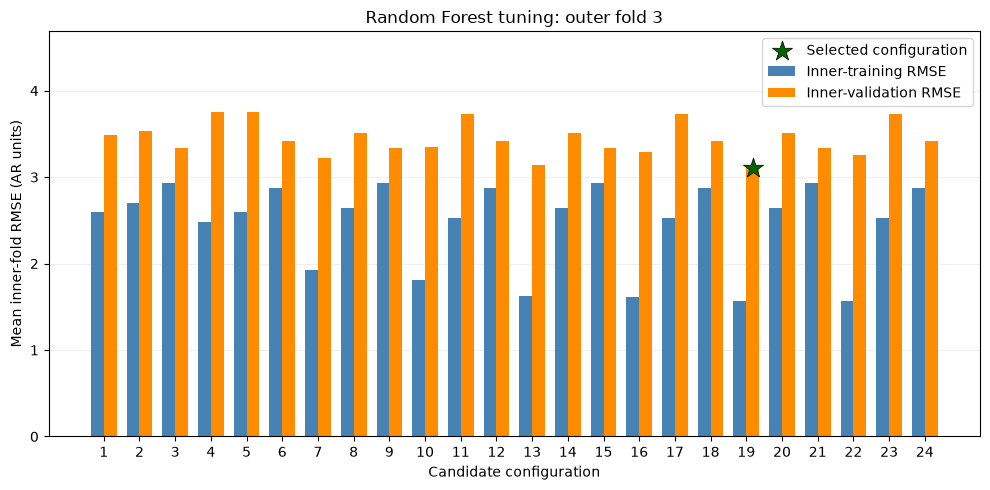

Selected candidate: 19
Selected settings: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}


,Candidate,max_depth,max_features,min_samples_leaf,Training RMSE,Validation RMSE
0,1,1,0.5,1,2.5979,3.4810
1,2,1,0.5,2,2.6985,3.5277
2,3,1,0.5,3,2.9358,3.3371
3,4,1,1.0,1,2.4838,3.7482
4,5,1,1.0,2,2.5939,3.7484
5,6,1,1.0,3,2.8684,3.4142
6,7,2,0.5,1,1.9230,3.2261
7,8,2,0.5,2,2.6454,3.5072
8,9,2,0.5,3,2.9358,3.3371
9,10,2,1.0,1,1.8074,3.3459


In [44]:
# Visualise RF training and validation errors during tuning

# Choose which completed outer-fold search to inspect: 1, 2 or 3
outer_fold_to_plot = 3

# Retrieve its saved search results
plot_search = rf_searches[outer_fold_to_plot - 1]
search_results = pd.DataFrame(plot_search.cv_results_)

# Create a table linking candidate numbers to their hyperparameters
rf_tuning_table = pd.DataFrame(
    search_results["params"].tolist(),
    dtype=object
)

candidate_numbers = np.arange(1, len(rf_tuning_table) + 1)
rf_tuning_table.insert(0, "Candidate", candidate_numbers)

# Convert negative scores back into positive RMSE values
rf_tuning_table["Training RMSE"] = (
    -search_results["mean_train_score"]
)

rf_tuning_table["Validation RMSE"] = (
    -search_results["mean_test_score"]
)

# Convert the selected candidate's zero-based index into its table number
selected_candidate = plot_search.best_index_ + 1

# Plot training and validation errors beside each other
bar_width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    candidate_numbers - bar_width / 2,
    rf_tuning_table["Training RMSE"],
    width=bar_width,
    color="steelblue",
    label="Inner-training RMSE"
)

ax.bar(
    candidate_numbers + bar_width / 2,
    rf_tuning_table["Validation RMSE"],
    width=bar_width,
    color="darkorange",
    label="Inner-validation RMSE"
)

# Mark the configuration selected by GridSearchCV
ax.scatter(
    selected_candidate + bar_width / 2,
    -plot_search.best_score_,
    marker="*",
    s=230,
    color="darkgreen",
    edgecolors="black",
    linewidths=0.5,
    zorder=5,
    label="Selected configuration"
)

ax.set_xticks(candidate_numbers)
ax.set_xlabel("Candidate configuration")
ax.set_ylabel("Mean inner-fold RMSE (AR units)")
ax.set_title(
    f"Random Forest tuning: outer fold {outer_fold_to_plot}"
)

# Leave space above the bars for the legend
ax.set_ylim(
    0,
    max(
        rf_tuning_table["Training RMSE"].max(),
        rf_tuning_table["Validation RMSE"].max()
    ) * 1.25
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

print("Selected candidate:", selected_candidate)
print("Selected settings:", plot_search.best_params_)

display(rf_tuning_table.round(4))

The candidate selected for each outer fold is the one with the lowest validation RMSE. 

This is because the validation RMSE tells us how accurately does the configuration predict the withheld inner-validation observations.

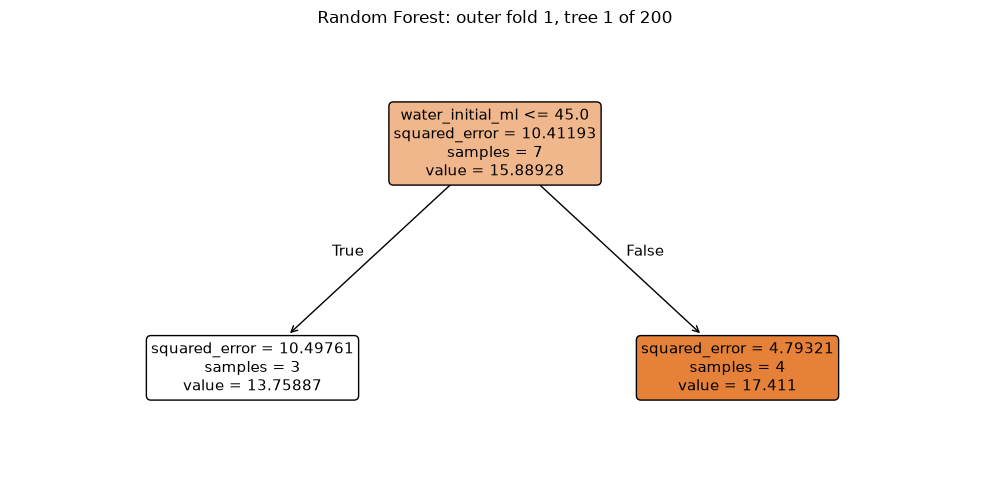

Selected RF settings: {'max_depth': 1, 'max_features': 0.5, 'min_samples_leaf': 3}
Distinct training runs in this tree: 7
Bootstrap draws, including repeats: 12


In [45]:
# Inspect one tree from a selected Random Forest

from sklearn.tree import plot_tree

# Choose the outer fold and tree to inspect
outer_fold_to_plot = 1
tree_number = 1

# Retrieve the selected forest, already fitted in Cell 16
selected_forest = (
    rf_searches[outer_fold_to_plot - 1].best_estimator_
)

# Retrieve one of the fitted trees
selected_tree = selected_forest.estimators_[tree_number - 1]

# Draw the complete tree
fig, ax = plt.subplots(figsize=(10, 5))

plot_tree(
    selected_tree,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    impurity=True,
    precision=5,
    fontsize=11,
    ax=ax
)

ax.set_title(
    f"Random Forest: outer fold {outer_fold_to_plot}, "
    f"tree {tree_number} of {len(selected_forest.estimators_)}"
)

plt.tight_layout()
plt.show()

# Display the selected settings and bootstrap sample counts
print(
    "Selected RF settings:",
    rf_searches[outer_fold_to_plot - 1].best_params_
)

print(
    "Distinct training runs in this tree:",
    selected_tree.tree_.n_node_samples[0]
)

print(
    "Bootstrap draws, including repeats:",
    int(selected_tree.tree_.weighted_n_node_samples[0])
)

This diagram shows one of 200 trees. Other trees may use different inputs and thresholds. This one tree therefore does not describe the entire forest’s behaviour.

Squared_error - describes the variation of the training AR values within a node.

value - is the average of the training AR values reaching that node, accounting for repeated bootstrap draws.

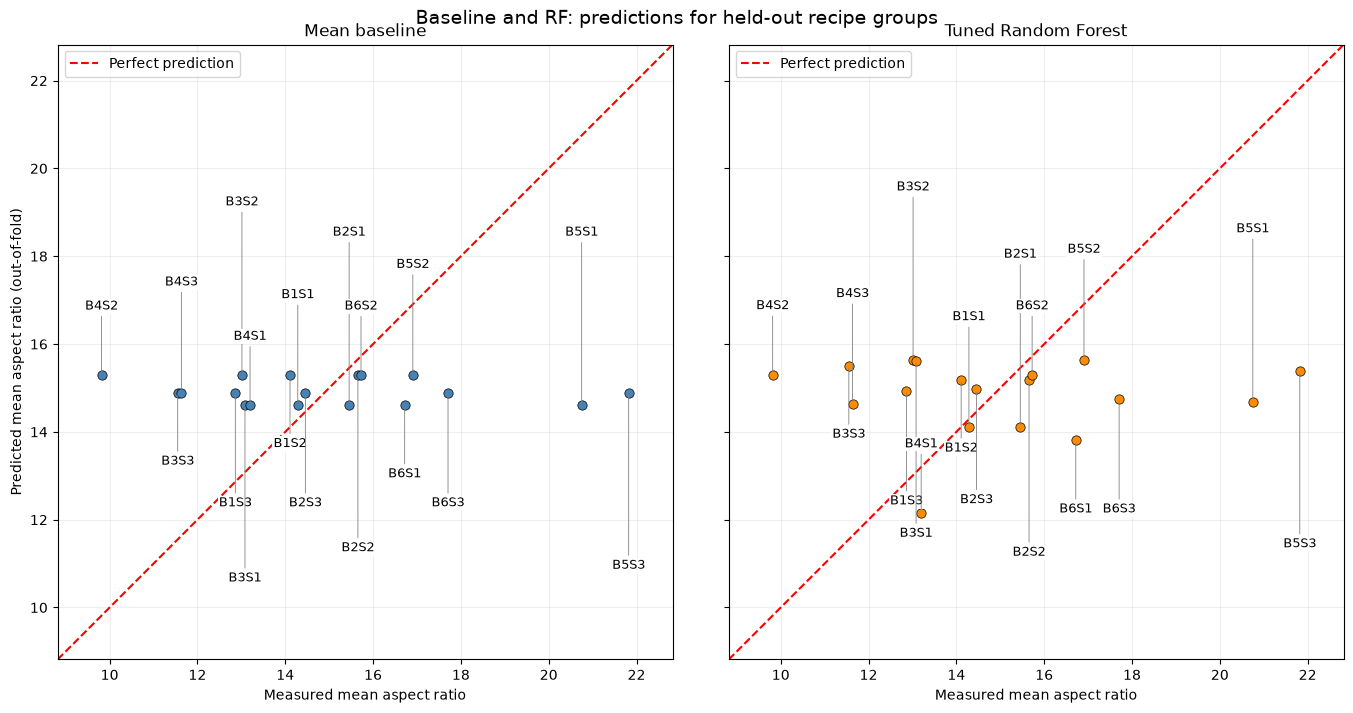

,Model,OOF MAE,OOF RMSE
0,Mean baseline,2.3618,3.0632
1,Tuned Random Forest,2.4651,3.1112


In [46]:
# Compare baseline and RF held-out predictions

# Keep each sample's measured value and both predictions together
prediction_table = pd.DataFrame({
    "Sample": data.loc[y.index, "notes"].to_numpy(),
    "Measured AR": y.to_numpy(),
    "Mean baseline": baseline_oof_predictions,
    "Tuned Random Forest": rf_oof_predictions
})

# Sort for consistent label placement
prediction_table = (
    prediction_table
    .sort_values("Measured AR")
    .reset_index(drop=True)
)

model_names = ["Mean baseline", "Tuned Random Forest"]
colors = ["steelblue", "darkorange"]

# Calculate common limits for both plots
lower = (
    prediction_table[["Measured AR"] + model_names].min().min() - 1
)

upper = (
    prediction_table[["Measured AR"] + model_names].max().max() + 1
)

# Stagger sample labels to reduce overlap
label_offsets = [45, -45, 75, -75, 120, -120]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7),
    sharex=True,
    sharey=True
)

# Draw one panel for each model
for ax, model_name, color in zip(axes, model_names, colors):

    ax.scatter(
        prediction_table["Measured AR"],
        prediction_table[model_name],
        color=color,
        edgecolors="black",
        linewidths=0.5,
        s=45,
        zorder=3
    )

    # Reference line for perfect predictions
    ax.plot(
        [lower, upper],
        [lower, upper],
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Perfect prediction"
    )

    # Label the observations using the notes column
    for i, row in prediction_table.iterrows():

        if pd.isna(row["Sample"]) or str(row["Sample"]).strip() == "":
            continue

        offset = label_offsets[i % len(label_offsets)]

        ax.annotate(
            str(row["Sample"]),
            xy=(row["Measured AR"], row[model_name]),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom" if offset > 0 else "top",
            fontsize=9,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "pad": 0.8
            },
            arrowprops={
                "arrowstyle": "-",
                "color": "gray",
                "lw": 0.6
            }
        )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Measured mean aspect ratio")
    ax.set_title(model_name)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")

axes[0].set_ylabel("Predicted mean aspect ratio (out-of-fold)")

fig.suptitle(
    "Baseline and RF: predictions for held-out recipe groups",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Display the numerical comparison alongside the plots
display(model_comparison.round(4))

In [50]:
# Define the two Gaussian Process models

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    Matern,
    RBF,
    WhiteKernel
)


# Settings shared by both Gaussian Process models
gp_settings = {
    "alpha": 1e-8,               # Small numerical stabilisation
    "normalize_y": True,        # Standardise AR internally during fitting
    "n_restarts_optimizer": 5,   # Additional attempts to optimise the kernel
    "random_state": 42          # Make the random starting points reproducible
}


# Matérn kernel: signal variance × similarity + observation noise
matern_kernel = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(1e-2, 1e2)
    )
    * Matern(
        length_scale=1.0,
        length_scale_bounds=(1e-2, 1e2),
        nu=1.5
    )
    + WhiteKernel(
        noise_level=0.1,
        noise_level_bounds=(1e-4, 1e1)
    )
)


# RBF kernel: signal variance × similarity + observation noise
rbf_kernel = (
    ConstantKernel(
        constant_value=1.0,
        constant_value_bounds=(1e-2, 1e2)
    )
    * RBF(
        length_scale=1.0,
        length_scale_bounds=(1e-2, 1e2)
    )
    + WhiteKernel(
        noise_level=0.1,
        noise_level_bounds=(1e-4, 1e1)
    )
)


# Keep input scaling inside each model's training pipeline
matern_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "gp",
        GaussianProcessRegressor(
            kernel=matern_kernel,
            **gp_settings
        )
    )
])

rbf_model = Pipeline([
    ("scale", StandardScaler()),
    (
        "gp",
        GaussianProcessRegressor(
            kernel=rbf_kernel,
            **gp_settings
        )
    )
])


# Display the initial kernels
print("Initial Matérn kernel:")
print(matern_model.named_steps["gp"].kernel)

print("\nInitial RBF kernel:")
print(rbf_model.named_steps["gp"].kernel)

Initial Matérn kernel:
1**2 * Matern(length_scale=1, nu=1.5) + WhiteKernel(noise_level=0.1)

Initial RBF kernel:
1**2 * RBF(length_scale=1) + WhiteKernel(noise_level=0.1)


| Code component | Role |
|---|---|
| `ConstantKernel(...)` | Sets the scale of variation in the underlying AR function. |
| `Matern(...)` or `RBF(...)` | Describes how similarity decreases as recipes become further apart. |
| `WhiteKernel(...)` | Allows individual run means to scatter around the underlying function. |

length_scale=1.0,
length_scale_bounds=(1e-2, 1e2)

This means that we start the length scale at 1.0, then allow the optimiser to search between 0.01 and 100.


In WhiteKernel, fitted noise can absorb some unexplained differences between nominally similar recipes. However, the model is not directly using the SEM particle standard deviations, because those values are not supplied to this model. It also cannot separate synthesis variability from measurement variability or automatically correct a systematic batch shift.

In [51]:
# Define the GP candidates for tuning

from sklearn.base import clone


# Count the input features in X
n_features = X.shape[1]


# ----- Matérn candidates -----

# Candidate 1: one shared length scale
matern_shared_kernel = clone(matern_kernel)

# Candidate 2: one length scale for each input
matern_separate_kernel = clone(matern_kernel)

matern_separate_kernel.set_params(
    k1__k2__length_scale=np.ones(n_features)
)


# ----- RBF candidates -----

# Candidate 1: one shared length scale
rbf_shared_kernel = clone(rbf_kernel)

# Candidate 2: one length scale for each input
rbf_separate_kernel = clone(rbf_kernel)

rbf_separate_kernel.set_params(
    k1__k2__length_scale=np.ones(n_features)
)


# Candidate lists for GridSearchCV
matern_param_grid = {
    "gp__kernel": [
        matern_shared_kernel,
        matern_separate_kernel
    ]
}

rbf_param_grid = {
    "gp__kernel": [
        rbf_shared_kernel,
        rbf_separate_kernel
    ]
}


# Summarise the two structures used for both GP models
gp_candidate_summary = pd.DataFrame({
    "Candidate": [1, 2],
    "Length-scale setup": [
        "One shared length scale",
        "One length scale per input"
    ],
    "Number of length scales": [
        1,
        n_features
    ],
    "Fitted kernel parameters": [
        3,
        n_features + 2
    ]
})

print("Input order:", X.columns.tolist())

gp_candidate_summary

Input order: ['time_h', 'hto_mass_g', 'baoh_mass_g', 'water_initial_ml']


,Candidate,Length-scale setup,Number of length scales,Fitted kernel parameters
0,1,One shared length scale,1,3
1,2,One length scale per input,4,6


Separate length scales are commonly called automatic relevance determination, or ARD. However, with only eight training runs in each inner fold, these values may be unstable.

| Position | Input | Initial length scale |
|---|---|---:|
| 1 | `time_h` | 1.0 |
| 2 | `hto_mass_g` | 1.0 |
| 3 | `baoh_mass_g` | 1.0 |
| 4 | `water_initial_ml` | 1.0 |


We are counting the kernel parameters fitted by the GP optimiser:

| Parameter type | Shared candidate | Separate candidate |
|---|---:|---:|
| Signal variance | 1 | 1 |
| Length scales | 1 | 4 |
| Noise variance | 1 | 1 |
| **Total** | **3** | **6** |

In [52]:
# Tune and evaluate the Matérn GP

# Store one held-out prediction for every observation
matern_oof_predictions = np.full(len(y), np.nan)

# Store the results and fitted search object for each outer fold
matern_fold_rows = []
matern_searches = []


# Use exactly the same outer folds as the baseline and RF
for fold, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    print(
        f"Fitting Matérn GP: outer fold {fold} of {len(cv_splits)}"
    )

    # Separate the current outer-training and held-out observations
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Compare the two kernel structures using the existing inner folds
    search = GridSearchCV(
        estimator=matern_model,
        param_grid=matern_param_grid,
        scoring=selection_scoring,
        cv=inner_cv_splits[fold - 1],
        refit=True,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise"
    )

    # Tune using only the current outer-training observations
    search.fit(X_train, y_train)

    # Predict the held-out observations using the selected, refitted model
    predictions = search.predict(X_test)

    # Place these predictions in their original row positions
    matern_oof_predictions[test_idx] = predictions

    # Save the search results and fitted model for later inspection
    matern_searches.append(search)

    # Identify which of the two kernel structures was selected
    selected_candidate = search.best_index_ + 1

    length_scale_setup = (
        "Shared"
        if selected_candidate == 1
        else "Separate per input"
    )

    # Record the results for this outer fold
    matern_fold_rows.append({
        "Fold": fold,
        "Selected candidate": selected_candidate,
        "Length-scale setup": length_scale_setup,
        "Inner CV RMSE": -search.best_score_,
        "Held-out MAE": mean_absolute_error(
            y_test,
            predictions
        ),
        "Held-out RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        )
    })


# Convert the fold results into a table
matern_fold_results = pd.DataFrame(matern_fold_rows)


# Calculate overall errors from all 18 held-out predictions
matern_results = pd.DataFrame([{
    "Model": "Tuned Matérn GP",
    "OOF MAE": mean_absolute_error(
        y,
        matern_oof_predictions
    ),
    "OOF RMSE": np.sqrt(
        mean_squared_error(y, matern_oof_predictions)
    )
}])


# Rebuild the comparison table to avoid duplicate rows when rerunning
model_comparison = pd.concat(
    [baseline_results, rf_results, matern_results],
    ignore_index=True
)


display(matern_fold_results.round(4))
display(model_comparison.round(4))

Fitting Matérn GP: outer fold 1 of 3
Fitting Matérn GP: outer fold 2 of 3


c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Fitting Matérn GP: outer fold 3 of 3


c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,Fold,Selected candidate,Length-scale setup,Inner CV RMSE,Held-out MAE,Held-out RMSE
0,1,1,Shared,2.2670,3.1343,3.6970
1,2,1,Shared,3.2203,1.8913,2.5667
2,3,2,Separate per input,2.9483,3.0006,3.8722


,Model,OOF MAE,OOF RMSE
0,Mean baseline,2.3618,3.0632
1,Tuned Random Forest,2.4651,3.1112
2,Tuned Matérn GP,2.6754,3.4278


In [53]:
# Inspect the fitted Matérn parameters

# Collect the fitted parameters from each outer-fold model
kernel_rows = []
length_scale_rows = []


for fold, search in enumerate(matern_searches, start=1):

    # Access the selected, fitted GP inside its pipeline
    fitted_gp = search.best_estimator_.named_steps["gp"]

    # The trailing underscore means these are the fitted kernel values
    fitted_kernel = fitted_gp.kernel_

    # Extract the signal variance and noise variance
    signal_variance = fitted_kernel.k1.k1.constant_value
    noise_variance = fitted_kernel.k2.noise_level

    # Convert either a single length scale or an array into an array
    length_scales = np.atleast_1d(
        fitted_kernel.k1.k2.length_scale
    )

    # Repeat a shared length scale across columns for display only
    if length_scales.size == 1:
        length_scale_setup = "Shared"
        length_scales = np.repeat(
            length_scales,
            X.shape[1]
        )
    else:
        length_scale_setup = "Separate per input"

    # Recover the AR scale used in this outer-training fold
    train_idx, _ = cv_splits[fold - 1]

    training_ar_sd = y.iloc[train_idx].std(ddof=0)

    # Convert fitted noise variance into noise SD in original AR units
    noise_sd_ar = np.sqrt(noise_variance) * training_ar_sd

    # Store the signal and noise information
    kernel_rows.append({
        "Fold": fold,
        "Length-scale setup": length_scale_setup,
        "Signal variance (normalised)": signal_variance,
        "Noise variance (normalised)": noise_variance,
        "Noise SD (AR units)": noise_sd_ar
    })

    # Store one displayed length scale for each input
    length_scale_row = {"Fold": fold}

    for feature, length_scale in zip(X.columns, length_scales):
        length_scale_row[feature] = length_scale

    length_scale_rows.append(length_scale_row)


# Create the two summary tables
matern_kernel_summary = (
    pd.DataFrame(kernel_rows)
    .set_index("Fold")
)

matern_length_scales = (
    pd.DataFrame(length_scale_rows)
    .set_index("Fold")
)


print("Fitted signal and noise parameters:")
display(matern_kernel_summary.round(4))

print("Fitted length scales in standardised input units:")
display(matern_length_scales.round(4))

Fitted signal and noise parameters:


,Length-scale setup,Signal variance (normalised),Noise variance (normalised),Noise SD (AR units)
Fold,,,,
1,Shared,1.0033,0.1521,1.0054
2,Shared,0.0100,0.9917,3.2084
3,Separate per input,1.0052,0.1134,1.0484


Fitted length scales in standardised input units:


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml
Fold,,,,
1,0.0793,0.0793,0.0793,0.0793
2,0.0100,0.0100,0.0100,0.0100
3,0.0100,0.0174,100.0000,100.0000


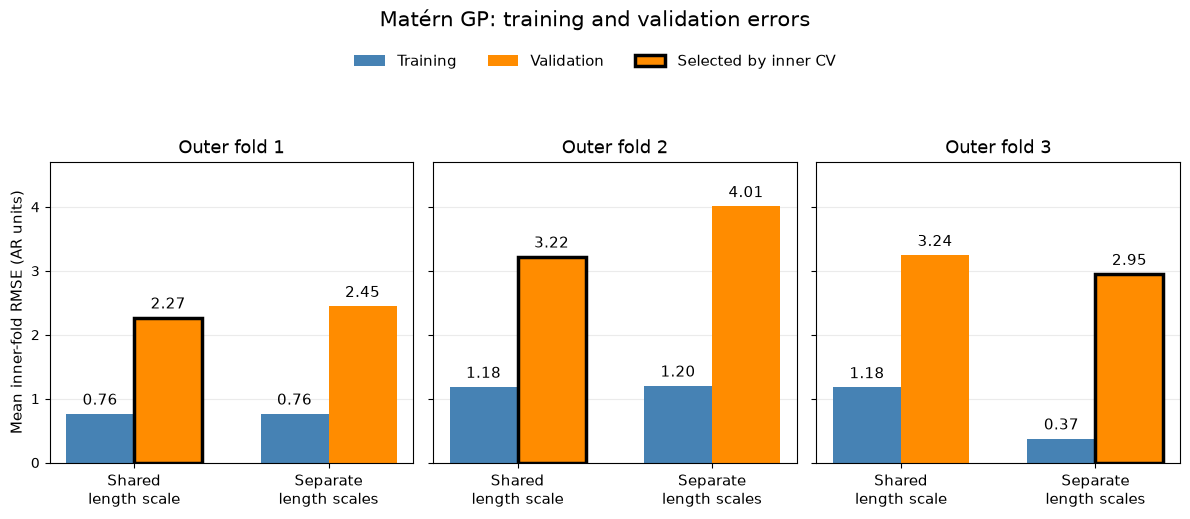

In [54]:
# Visualise the Matérn tuning results

from matplotlib.patches import Patch


# Labels follow the candidate order defined in in previous cell
candidate_labels = [
    "Shared\nlength scale",
    "Separate\nlength scales"
]

x = np.arange(len(candidate_labels))
bar_width = 0.35


# Create one panel for each outer fold
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 5.2),
    sharey=True
)

largest_error = 0


for fold, (ax, search) in enumerate(
    zip(axes, matern_searches),
    start=1
):

    # Read the scores saved during the inner CV search
    results = search.cv_results_

    # Convert negative RMSE scores back into positive RMSE
    training_rmse = -results["mean_train_score"]
    validation_rmse = -results["mean_test_score"]

    # Blue bars: average inner-training RMSE
    training_bars = ax.bar(
        x - bar_width / 2,
        training_rmse,
        width=bar_width,
        color="steelblue"
    )

    # Orange bars: average inner-validation RMSE
    validation_bars = ax.bar(
        x + bar_width / 2,
        validation_rmse,
        width=bar_width,
        color="darkorange"
    )

    # Outline the candidate selected by inner CV
    selected_bar = validation_bars[search.best_index_]

    selected_bar.set_edgecolor("black")
    selected_bar.set_linewidth(2.5)

    # Display the RMSE above each bar
    ax.bar_label(
        training_bars,
        fmt="%.2f",
        padding=4,
        fontsize=11
    )

    ax.bar_label(
        validation_bars,
        fmt="%.2f",
        padding=4,
        fontsize=11
    )

    ax.set_xticks(x)
    ax.set_xticklabels(candidate_labels, fontsize=11)

    ax.set_title(f"Outer fold {fold}", fontsize=13)

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

    # Track the largest value to set a common vertical-axis limit
    largest_error = max(
        largest_error,
        training_rmse.max(),
        validation_rmse.max()
    )


axes[0].set_ylabel(
    "Mean inner-fold RMSE (AR units)",
    fontsize=11
)

axes[0].set_ylim(0, largest_error + 0.7)


# Create a legend symbol for the selected candidate
selected_key = Patch(
    facecolor="darkorange",
    edgecolor="black",
    linewidth=2.5
)

fig.legend(
    [training_bars, validation_bars, selected_key],
    ["Training", "Validation", "Selected by inner CV"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "Matérn GP: training and validation errors",
    fontsize=15,
    y=0.99
)

fig.tight_layout(rect=[0, 0, 1, 0.84])

plt.show()

The main finding is that separate length scales help in one outer fold 3's inner search but hurt in the other two. 

So there is no consistent evidence that adding this flexibility improves prediction.

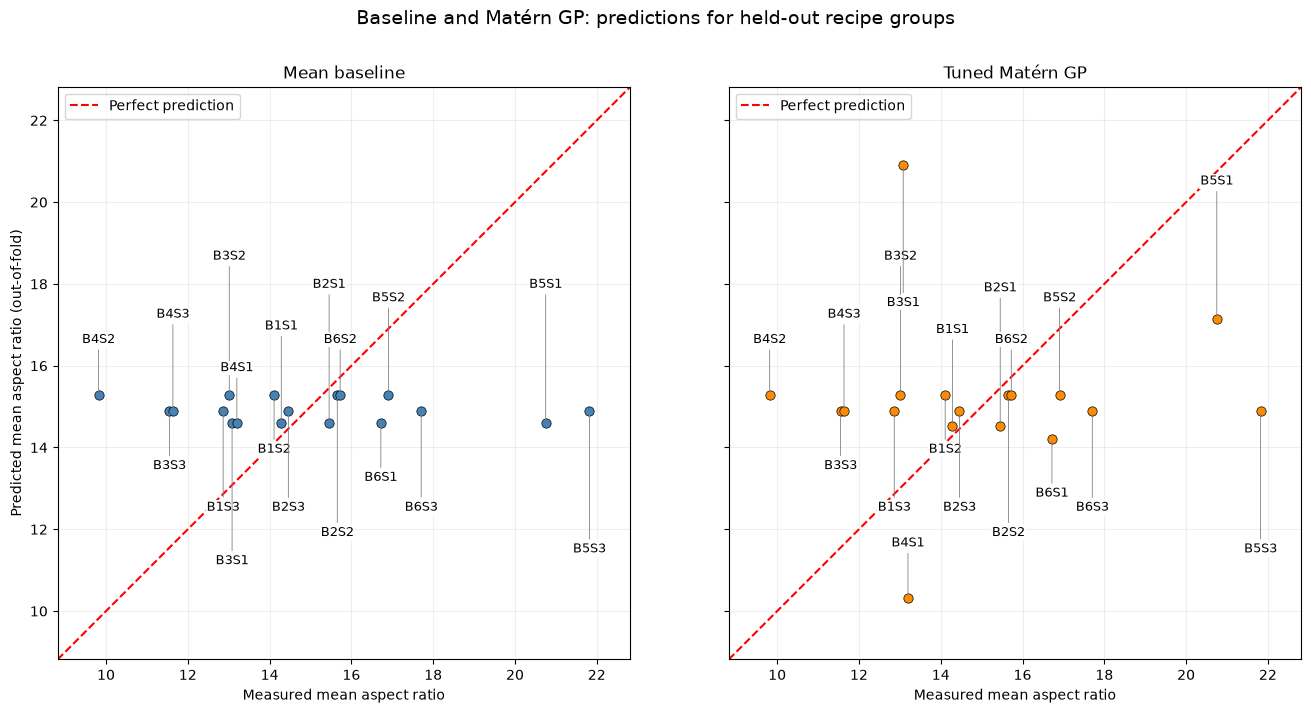

In [56]:
# Comparison with baseline

# Keep measured values, predictions and sample labels together
matern_prediction_table = pd.DataFrame({
    "Sample": data.loc[y.index, "notes"].to_numpy(),
    "Measured AR": y.to_numpy(),
    "Mean baseline": baseline_oof_predictions,
    "Tuned Matérn GP": matern_oof_predictions
})

# Sort complete rows so labels remain matched to their predictions
matern_prediction_table = (
    matern_prediction_table
    .sort_values("Measured AR")
    .reset_index(drop=True)
)


model_names = [
    "Mean baseline",
    "Tuned Matérn GP"
]

colors = [
    "steelblue",
    "darkorange"
]


# Use identical limits for both plots and both axes
plot_columns = ["Measured AR"] + model_names

lower = matern_prediction_table[plot_columns].min().min() - 1
upper = matern_prediction_table[plot_columns].max().max() + 1


# Stagger the sample labels vertically to reduce overlap
label_offsets = [35, -35, 65, -65, 95, -95]


fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7),
    sharex=True,
    sharey=True
)


for ax, model_name, color in zip(axes, model_names, colors):

    # Each point is one held-out prediction
    ax.scatter(
        matern_prediction_table["Measured AR"],
        matern_prediction_table[model_name],
        color=color,
        edgecolors="black",
        linewidths=0.5,
        s=45,
        zorder=3
    )

    # Perfect prediction: predicted AR equals measured AR
    ax.plot(
        [lower, upper],
        [lower, upper],
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Perfect prediction"
    )

    # Label each point using the notes column
    for i, row in matern_prediction_table.iterrows():

        if pd.isna(row["Sample"]) or str(row["Sample"]).strip() == "":
            continue

        offset = label_offsets[i % len(label_offsets)]

        ax.annotate(
            text=str(row["Sample"]),
            xy=(row["Measured AR"], row[model_name]),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom" if offset > 0 else "top",
            fontsize=9,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "pad": 0.8
            },
            arrowprops={
                "arrowstyle": "-",
                "color": "gray",
                "lw": 0.6
            }
        )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

    # Make one AR unit the same visual distance on both axes
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Measured mean aspect ratio")
    ax.set_title(model_name)

    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")


axes[0].set_ylabel(
    "Predicted mean aspect ratio (out-of-fold)"
)

fig.suptitle(
    "Baseline and Matérn GP: predictions for held-out recipe groups",
    fontsize=14
)

# Leave room above the panels for the overall title
fig.tight_layout(rect=[0, 0, 1, 0.94])

plt.show()

In [55]:
# Tune and evaluate the RBF GP

# Store one held-out prediction for every observation
rbf_oof_predictions = np.full(len(y), np.nan)

# Store results and fitted search objects for the three outer folds
rbf_fold_rows = []
rbf_searches = []


# Use the same outer folds as the other models
for fold, (train_idx, test_idx) in enumerate(cv_splits, start=1):

    print(
        f"Fitting RBF GP: outer fold {fold} of {len(cv_splits)}"
    )

    # Separate the current outer-training and held-out observations
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Compare the two RBF kernel structures using the same inner folds
    search = GridSearchCV(
        estimator=rbf_model,
        param_grid=rbf_param_grid,
        scoring=selection_scoring,
        cv=inner_cv_splits[fold - 1],
        refit=True,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise"
    )

    # Tune using only the current outer-training observations
    search.fit(X_train, y_train)

    # Predict the six held-out observations
    predictions = search.predict(X_test)

    # Store predictions in their original observation positions
    rbf_oof_predictions[test_idx] = predictions

    # Save the fitted search object for later inspection
    rbf_searches.append(search)

    # Identify the selected kernel structure
    selected_candidate = search.best_index_ + 1

    length_scale_setup = (
        "Shared"
        if selected_candidate == 1
        else "Separate per input"
    )

    # Record the results for this outer fold
    rbf_fold_rows.append({
        "Fold": fold,
        "Selected candidate": selected_candidate,
        "Length-scale setup": length_scale_setup,
        "Inner CV RMSE": -search.best_score_,
        "Held-out MAE": mean_absolute_error(
            y_test,
            predictions
        ),
        "Held-out RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        )
    })


# Create the table of results for individual outer folds
rbf_fold_results = pd.DataFrame(rbf_fold_rows)


# Calculate overall errors using all 18 held-out predictions
rbf_results = pd.DataFrame([{
    "Model": "Tuned RBF GP",
    "OOF MAE": mean_absolute_error(
        y,
        rbf_oof_predictions
    ),
    "OOF RMSE": np.sqrt(
        mean_squared_error(y, rbf_oof_predictions)
    )
}])


# Rebuild the comparison table with all four models
model_comparison = pd.concat(
    [
        baseline_results,
        rf_results,
        matern_results,
        rbf_results
    ],
    ignore_index=True
)


display(rbf_fold_results.round(4))
display(model_comparison.round(4))

Fitting RBF GP: outer fold 1 of 3
Fitting RBF GP: outer fold 2 of 3


c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Fitting RBF GP: outer fold 3 of 3


c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,Fold,Selected candidate,Length-scale setup,Inner CV RMSE,Held-out MAE,Held-out RMSE
0,1,1,Shared,2.2670,3.1343,3.6970
1,2,1,Shared,3.2203,1.8913,2.5667
2,3,2,Separate per input,2.9357,2.0785,2.6958


,Model,OOF MAE,OOF RMSE
0,Mean baseline,2.3618,3.0632
1,Tuned Random Forest,2.4651,3.1112
2,Tuned Matérn GP,2.6754,3.4278
3,Tuned RBF GP,2.3680,3.0289


From the results comparison, we can observe that RBF has the lowest observed OOF RMSE, while the baseline has the lowest observed OOF MAE.

RMSE as our primary criterion before this comparison, so RBF currently ranks first on that criterion. However, its advantage over the baseline is only about 0.034 AR units, or approximately 1.1%.

In [59]:
# Inspect the fitted RBF parameters

# Collect the fitted parameters from each outer-fold model
kernel_rows = []
length_scale_rows = []


for fold, search in enumerate(rbf_searches, start=1):

    # Access the selected, fitted GP inside its pipeline
    fitted_gp = search.best_estimator_.named_steps["gp"]

    # Access the kernel containing the learned parameter values
    fitted_kernel = fitted_gp.kernel_

    # Extract signal and noise variances
    signal_variance = fitted_kernel.k1.k1.constant_value
    noise_variance = fitted_kernel.k2.noise_level

    # Handle both a shared scalar and an array of separate length scales
    length_scales = np.atleast_1d(
        fitted_kernel.k1.k2.length_scale
    )

    # Repeat a shared value across columns for display only
    if length_scales.size == 1:
        length_scale_setup = "Shared"

        length_scales = np.repeat(
            length_scales,
            X.shape[1]
        )

    else:
        length_scale_setup = "Separate per input"

    # Calculate the target scale used in this outer-training fold
    train_idx, _ = cv_splits[fold - 1]

    training_ar_sd = y.iloc[train_idx].std(ddof=0)

    # Convert fitted noise variance into SD in original AR units
    noise_sd_ar = np.sqrt(noise_variance) * training_ar_sd

    # Store signal and noise information
    kernel_rows.append({
        "Fold": fold,
        "Length-scale setup": length_scale_setup,
        "Signal variance (normalised)": signal_variance,
        "Noise variance (normalised)": noise_variance,
        "Noise SD (AR units)": noise_sd_ar
    })

    # Store one displayed length scale for each input
    length_scale_row = {"Fold": fold}

    for feature, length_scale in zip(X.columns, length_scales):
        length_scale_row[feature] = length_scale

    length_scale_rows.append(length_scale_row)


# Create the summary tables
rbf_kernel_summary = (
    pd.DataFrame(kernel_rows)
    .set_index("Fold")
)

rbf_length_scales = (
    pd.DataFrame(length_scale_rows)
    .set_index("Fold")
)


print("Fitted signal and noise parameters:")
display(rbf_kernel_summary.round(4))

print("Fitted length scales in standardised input units:")
display(rbf_length_scales.round(4))

Fitted signal and noise parameters:


,Length-scale setup,Signal variance (normalised),Noise variance (normalised),Noise SD (AR units)
Fold,,,,
1,Shared,1.0033,0.1521,1.0054
2,Shared,0.0100,0.9920,3.2089
3,Separate per input,1.0960,0.1282,1.1143


Fitted length scales in standardised input units:


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml
Fold,,,,
1,0.1291,0.1291,0.1291,0.1291
2,0.0100,0.0100,0.0100,0.0100
3,1.4062,0.0149,100.0000,0.0121


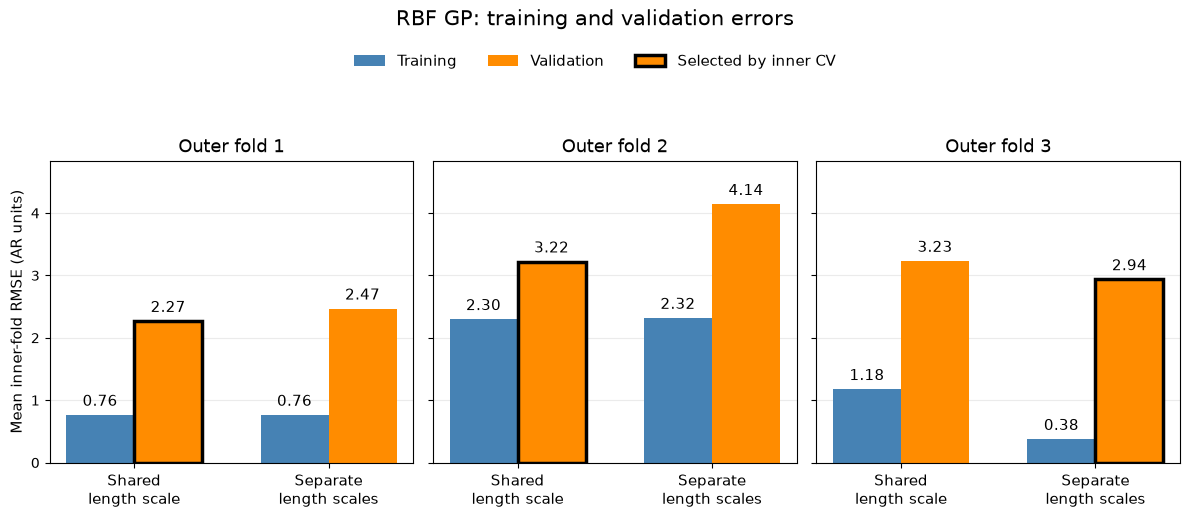

In [58]:
# Visualise RBF GP tuning results

# Labels follow the candidate order defined in the RBF parameter grid
candidate_labels = [
    "Shared\nlength scale",
    "Separate\nlength scales"
]

x = np.arange(len(candidate_labels))
bar_width = 0.35


# Create one panel for each outer fold
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 5.2),
    sharey=True
)

largest_error = 0


for fold, (ax, search) in enumerate(
    zip(axes, rbf_searches),
    start=1
):

    # Read the scores saved during the inner CV search
    results = search.cv_results_

    # Convert negative RMSE scores back into positive RMSE
    training_rmse = -results["mean_train_score"]
    validation_rmse = -results["mean_test_score"]

    # Blue bars: average inner-training RMSE
    training_bars = ax.bar(
        x - bar_width / 2,
        training_rmse,
        width=bar_width,
        color="steelblue"
    )

    # Orange bars: average inner-validation RMSE
    validation_bars = ax.bar(
        x + bar_width / 2,
        validation_rmse,
        width=bar_width,
        color="darkorange"
    )

    # Outline the candidate selected by inner CV
    selected_bar = validation_bars[search.best_index_]

    selected_bar.set_edgecolor("black")
    selected_bar.set_linewidth(2.5)

    # Display the RMSE above each bar
    ax.bar_label(
        training_bars,
        fmt="%.2f",
        padding=4,
        fontsize=11
    )

    ax.bar_label(
        validation_bars,
        fmt="%.2f",
        padding=4,
        fontsize=11
    )

    ax.set_xticks(x)
    ax.set_xticklabels(candidate_labels, fontsize=11)

    ax.set_title(f"Outer fold {fold}", fontsize=13)

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

    # Track the largest error to set a common vertical-axis limit
    largest_error = max(
        largest_error,
        training_rmse.max(),
        validation_rmse.max()
    )


axes[0].set_ylabel(
    "Mean inner-fold RMSE (AR units)",
    fontsize=11
)

axes[0].set_ylim(0, largest_error + 0.7)


# Create a legend symbol for the selected candidate
selected_key = Patch(
    facecolor="darkorange",
    edgecolor="black",
    linewidth=2.5
)

fig.legend(
    [training_bars, validation_bars, selected_key],
    ["Training", "Validation", "Selected by inner CV"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=3,
    frameon=False,
    fontsize=11
)

fig.suptitle(
    "RBF GP: training and validation errors",
    fontsize=15,
    y=0.99
)

fig.tight_layout(rect=[0, 0, 1, 0.84])

plt.show()

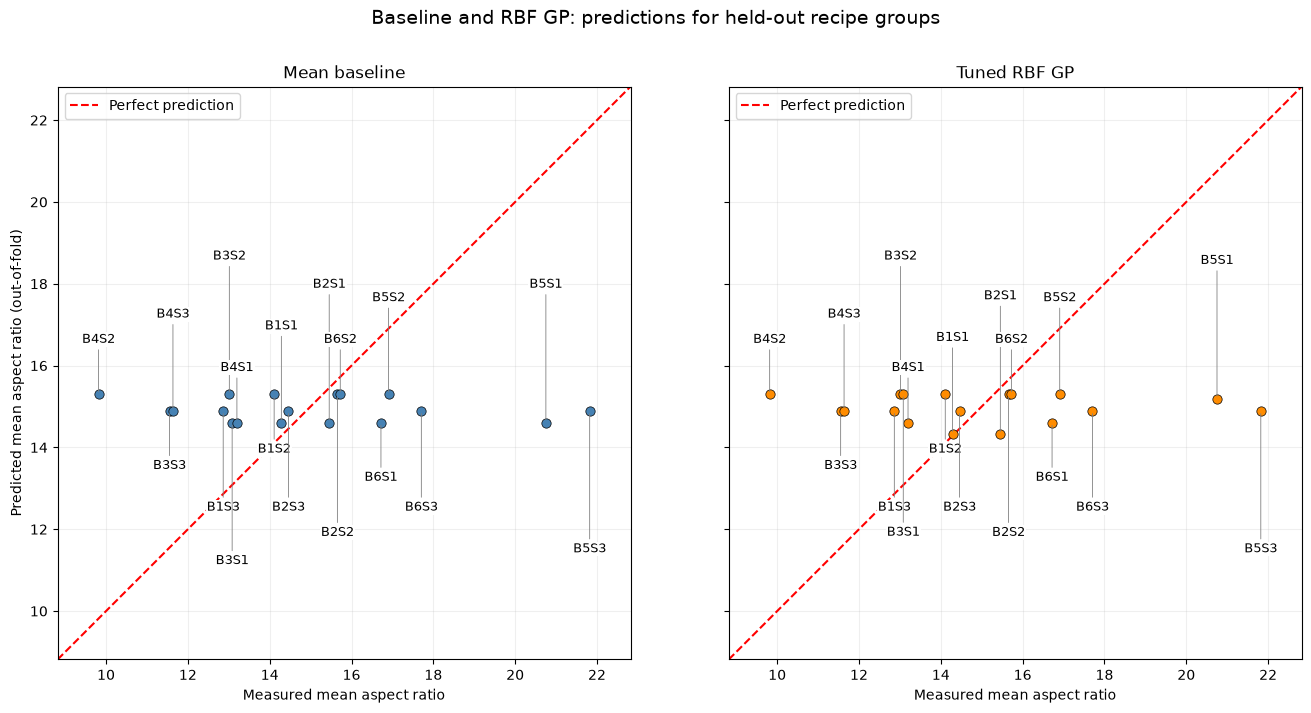

,Model,OOF MAE,OOF RMSE
0,Mean baseline,2.3618,3.0632
1,Tuned RBF GP,2.3680,3.0289


In [57]:
# Compare baseline and RBF predictions

# Keep sample labels, measured values and predictions together
rbf_prediction_table = pd.DataFrame({
    "Sample": data.loc[y.index, "notes"].to_numpy(),
    "Measured AR": y.to_numpy(),
    "Mean baseline": baseline_oof_predictions,
    "Tuned RBF GP": rbf_oof_predictions
})

# Sort complete rows so labels stay matched to their predictions
rbf_prediction_table = (
    rbf_prediction_table
    .sort_values("Measured AR")
    .reset_index(drop=True)
)


model_names = [
    "Mean baseline",
    "Tuned RBF GP"
]

colors = [
    "steelblue",
    "darkorange"
]


# Use identical limits for both panels and both axes
plot_columns = ["Measured AR"] + model_names

lower = rbf_prediction_table[plot_columns].min().min() - 1
upper = rbf_prediction_table[plot_columns].max().max() + 1


# Stagger sample labels vertically to reduce overlap
label_offsets = [35, -35, 65, -65, 95, -95]


fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7),
    sharex=True,
    sharey=True
)


for ax, model_name, color in zip(axes, model_names, colors):

    # Each point represents one held-out prediction
    ax.scatter(
        rbf_prediction_table["Measured AR"],
        rbf_prediction_table[model_name],
        color=color,
        edgecolors="black",
        linewidths=0.5,
        s=45,
        zorder=3
    )

    # Perfect prediction: predicted AR equals measured AR
    ax.plot(
        [lower, upper],
        [lower, upper],
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Perfect prediction"
    )

    # Label each point using the notes column
    for i, row in rbf_prediction_table.iterrows():

        if pd.isna(row["Sample"]) or str(row["Sample"]).strip() == "":
            continue

        offset = label_offsets[i % len(label_offsets)]

        ax.annotate(
            text=str(row["Sample"]),
            xy=(row["Measured AR"], row[model_name]),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            va="bottom" if offset > 0 else "top",
            fontsize=9,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "pad": 0.8
            },
            arrowprops={
                "arrowstyle": "-",
                "color": "gray",
                "lw": 0.6
            }
        )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)

    # Make one AR unit the same visual distance on both axes
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Measured mean aspect ratio")
    ax.set_title(model_name)

    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")


axes[0].set_ylabel(
    "Predicted mean aspect ratio (out-of-fold)"
)

fig.suptitle(
    "Baseline and RBF GP: predictions for held-out recipe groups",
    fontsize=14
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

plt.show()


# Display the corresponding numerical comparison
display(
    pd.concat(
        [baseline_results, rbf_results],
        ignore_index=True
    ).round(4)
)

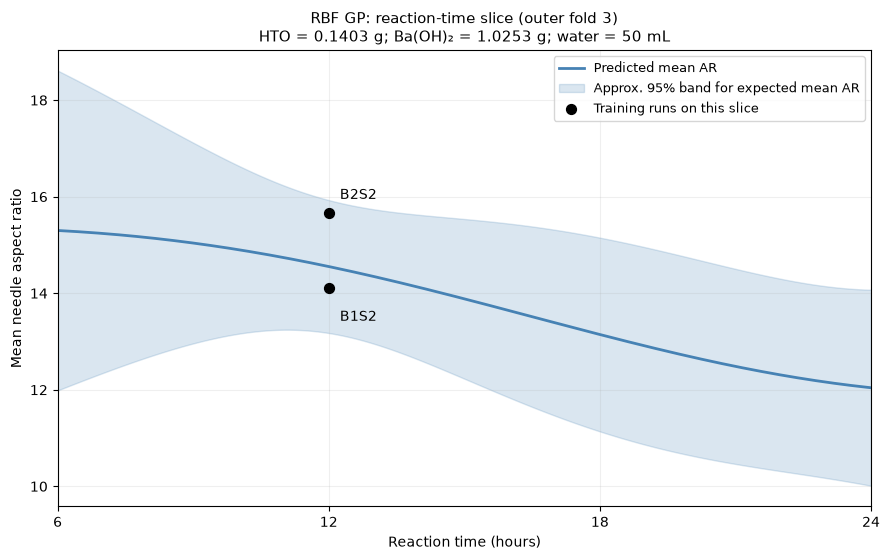

Model trained on 12 runs; 2 lie exactly on this slice.


In [ ]:
# Visualise a RBF prediction curve

# Choose a fitted model and a reference training recipe
outer_fold_to_plot = 3 # 1 or 2 or 3
reference_row = 0 # Index of the recipe to hold fixed (0-5). reference_row = 0 selects the first recipe in outer fold 3's training set, which is B1S2.

plot_pipeline = (
    rbf_searches[outer_fold_to_plot - 1]
    .best_estimator_
)


# Retrieve the observations used to fit this outer-fold model
train_idx, _ = cv_splits[outer_fold_to_plot - 1]

X_train_slice = X.iloc[train_idx].copy()
y_train_slice = y.iloc[train_idx].copy()

reference = X_train_slice.iloc[reference_row]

fixed_features = [
    "hto_mass_g",
    "baoh_mass_g",
    "water_initial_ml"
]


# Create 400 reaction times at which to request predictions
time_grid = np.linspace(
    X_train_slice["time_h"].min(),
    X_train_slice["time_h"].max(),
    400
)

# Repeat the reference recipe, then change only reaction time
X_grid = pd.DataFrame(
    [reference.to_dict()] * len(time_grid)
)

X_grid["time_h"] = time_grid


# Obtain predictions and predictive standard deviations
prediction_mean, observation_std = plot_pipeline.predict(
    X_grid,
    return_std=True
)


# Convert fitted noise variance into original AR units
fitted_gp = plot_pipeline.named_steps["gp"]

noise_variance_ar = (
    fitted_gp.kernel_.k2.noise_level
    * y_train_slice.std(ddof=0) ** 2
)

# Remove observation noise to obtain uncertainty in the mean function
function_std = np.sqrt(
    np.maximum(
        observation_std ** 2 - noise_variance_ar,
        0.0
    )
)

lower_band = prediction_mean - 1.96 * function_std
upper_band = prediction_mean + 1.96 * function_std


# Identify training observations that lie exactly on this slice
on_slice = (
    X_train_slice[fixed_features]
    .eq(reference[fixed_features], axis="columns")
    .all(axis=1)
)


# Plot the predicted function
fig, ax = plt.subplots(figsize=(9, 5.7))

ax.plot(
    time_grid,
    prediction_mean,
    color="steelblue",
    linewidth=2,
    label="Predicted mean AR"
)

ax.fill_between(
    time_grid,
    lower_band,
    upper_band,
    color="steelblue",
    alpha=0.2,
    label="Approx. 95% band for expected mean AR"
)

ax.scatter(
    X_train_slice.loc[on_slice, "time_h"],
    y_train_slice.loc[on_slice],
    color="black",
    s=50,
    zorder=3,
    label="Training runs on this slice"
)


# Label the displayed observations
for i, idx in enumerate(X_train_slice.index[on_slice]):

    if pd.isna(data.loc[idx, "notes"]):
        continue

    label_offset = -16 if i % 2 == 0 else 8

    ax.annotate(
        str(data.loc[idx, "notes"]),
        xy=(
            X_train_slice.loc[idx, "time_h"],
            y_train_slice.loc[idx]
        ),
        xytext=(8, label_offset),
        textcoords="offset points",
        va="top" if label_offset < 0 else "bottom",
        fontsize=10
    )


ax.set_xlabel("Reaction time (hours)")
ax.set_ylabel("Mean needle aspect ratio")

ax.set_title(
    f"RBF GP: reaction-time slice (outer fold {outer_fold_to_plot})\n"
    f"HTO = {reference['hto_mass_g']:.4f} g; "
    f"Ba(OH)₂ = {reference['baoh_mass_g']:.4f} g; "
    f"water = {reference['water_initial_ml']:g} mL",
    fontsize=11
)

ax.set_xlim(time_grid.min(), time_grid.max())
ax.set_xticks([6, 12, 18, 24])

ax.grid(alpha=0.2)
ax.legend(loc="upper right", fontsize=9)

fig.tight_layout()
plt.show()

print(
    f"Model trained on {len(X_train_slice)} runs; "
    f"{on_slice.sum()} lie exactly on this slice."
)

c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Li

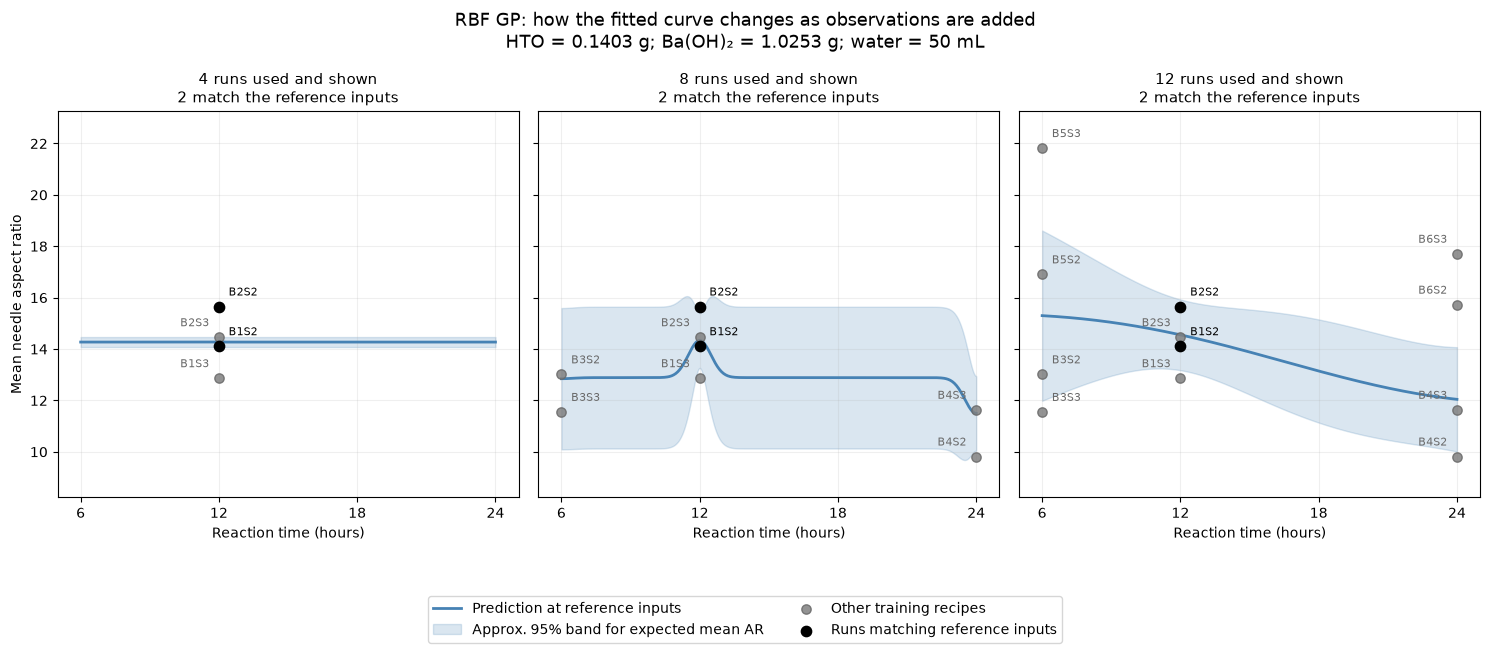

In [62]:
# Visualise how the training changes as more observations are added

# 1. Choose the training pool and observation counts
outer_fold_to_plot = 3
observation_counts = [4, 8, 12]

train_idx, _ = cv_splits[outer_fold_to_plot - 1]

X_training_pool = X.iloc[train_idx].copy()
y_training_pool = y.iloc[train_idx].copy()

# 2. Define the reference recipe and prediction grid
reference = X_training_pool.iloc[0]

fixed_features = [
    "hto_mass_g",
    "baoh_mass_g",
    "water_initial_ml"
]

time_grid = np.linspace(6, 24, 400)

X_grid = pd.DataFrame(
    [reference.to_dict()] * len(time_grid)
)

X_grid["time_h"] = time_grid

# Create panels with matching axis scales
fig, axes = plt.subplots(
    1,
    len(observation_counts),
    figsize=(15, 6.5),
    sharex=True,
    sharey=True
)

evolution_models = []

# 3. Fit a fresh model at each stage
for ax, n_observations in zip(axes, observation_counts):

    X_subset = X_training_pool.iloc[:n_observations]
    y_subset = y_training_pool.iloc[:n_observations]

    stage_model = clone(rbf_model)

    stage_model.set_params(
        gp__kernel=clone(rbf_separate_kernel)
    )

    stage_model.fit(X_subset, y_subset)
    evolution_models.append(stage_model)

    # Predict along the reference recipe's reaction-time slice
    prediction_mean, observation_std = stage_model.predict(
        X_grid,
        return_std=True
    )

    # Calculate uncertainty in the underlying expected response
    fitted_gp = stage_model.named_steps["gp"]

    noise_variance_ar = (
        fitted_gp.kernel_.k2.noise_level
        * y_subset.std(ddof=0) ** 2
    )

    function_std = np.sqrt(
        np.maximum(
            observation_std ** 2 - noise_variance_ar,
            0.0
        )
    )

    # 4. Draw the reference prediction and uncertainty band
    ax.plot(
        time_grid,
        prediction_mean,
        color="steelblue",
        linewidth=2,
        label="Prediction at reference inputs"
    )

    ax.fill_between(
        time_grid,
        prediction_mean - 1.96 * function_std,
        prediction_mean + 1.96 * function_std,
        color="steelblue",
        alpha=0.2,
        label="Approx. 95% band for expected mean AR"
    )

    # Identify observations matching all three fixed inputs
    on_slice = (
        X_subset[fixed_features]
        .eq(reference[fixed_features], axis="columns")
        .all(axis=1)
    )

    # Grey points: other recipes included in training
    ax.scatter(
        X_subset.loc[~on_slice, "time_h"],
        y_subset.loc[~on_slice],
        color="grey",
        edgecolors="dimgray",
        s=45,
        alpha=0.85,
        zorder=3,
        label="Other training recipes"
    )

    # Black points: runs matching the reference inputs
    ax.scatter(
        X_subset.loc[on_slice, "time_h"],
        y_subset.loc[on_slice],
        color="black",
        s=55,
        zorder=4,
        label="Runs matching reference inputs"
    )

    # 5. Label every observation using the notes column
    for idx in X_subset.index:

        if pd.isna(data.loc[idx, "notes"]):
            continue

        reaction_time = X_subset.loc[idx, "time_h"]
        matches_reference = on_slice.loc[idx]

        # Keep labels near the edges pointing into the plot
        if reaction_time == time_grid.min():
            offset_x = 7
        elif reaction_time == time_grid.max():
            offset_x = -7
        else:
            offset_x = 7 if matches_reference else -7

        ax.annotate(
            str(data.loc[idx, "notes"]),
            xy=(reaction_time, y_subset.loc[idx]),
            xytext=(offset_x, 6),
            textcoords="offset points",
            ha="left" if offset_x > 0 else "right",
            va="bottom",
            color="black" if matches_reference else "dimgray",
            fontsize=8
        )

    ax.set_title(
        f"{n_observations} runs used and shown\n"
        f"{on_slice.sum()} match the reference inputs",
        fontsize=11
    )

    ax.set_xlabel("Reaction time (hours)")
    ax.set_xlim(5, 25)
    ax.set_xticks([6, 12, 18, 24])
    ax.margins(y=0.12)
    ax.grid(alpha=0.2)

# 6. Add shared labels and a common legend
axes[0].set_ylabel("Mean needle aspect ratio")

fig.suptitle(
    "RBF GP: how the fitted curve changes as observations are added\n"
    f"HTO = {reference['hto_mass_g']:.4f} g; "
    f"Ba(OH)₂ = {reference['baoh_mass_g']:.4f} g; "
    f"water = {reference['water_initial_ml']:g} mL",
    fontsize=13
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    fontsize=10
)

fig.tight_layout(rect=[0, 0.14, 1, 1])

plt.show()

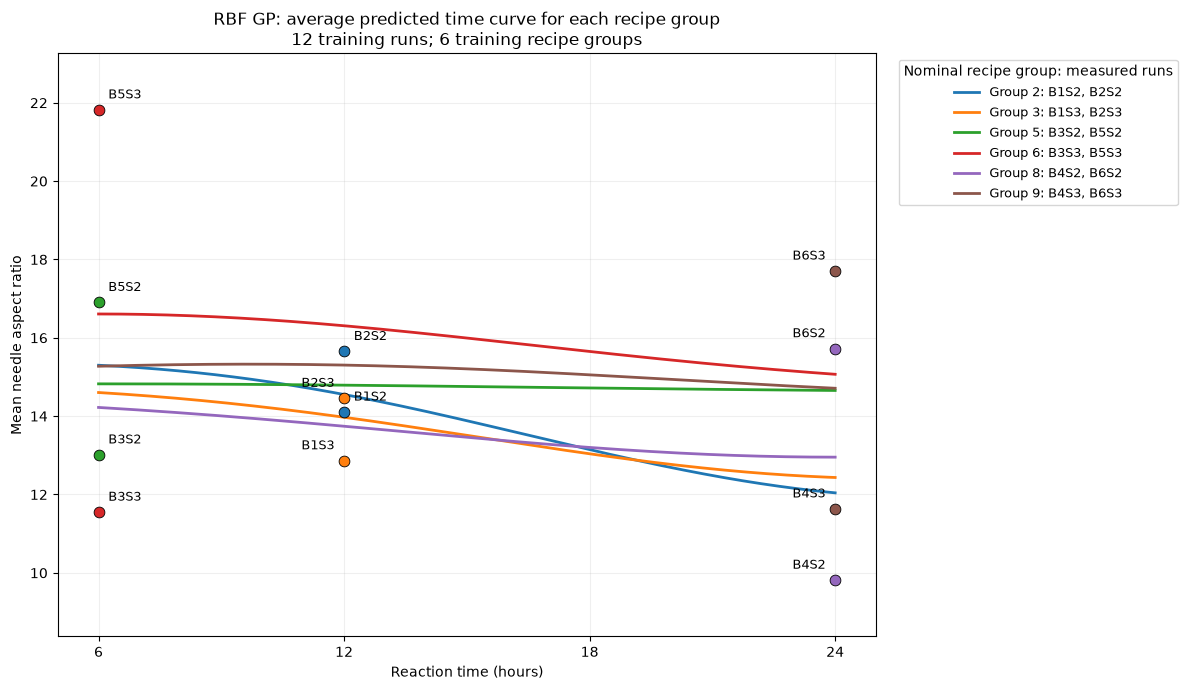

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Select the existing 12-run RBF model
stage_index = 2

plot_model = evolution_models[stage_index]
n_observations = observation_counts[stage_index]

X_subset = X_training_pool.iloc[:n_observations]
y_subset = y_training_pool.iloc[:n_observations]

# Retrieve recipe-group labels for these training rows
groups_subset = data.loc[
    X_subset.index,
    "recipe_group"
]

group_ids = sorted(groups_subset.unique())

time_grid = np.linspace(6, 24, 400)
colours = plt.get_cmap("tab10").colors

fig, ax = plt.subplots(figsize=(12, 7))

# Store the calculated group curves for later inspection
group_curves = {}

# 2. Construct one average prediction curve per recipe group
for i, group_id in enumerate(group_ids):

    group_indices = groups_subset.index[
        groups_subset == group_id
    ]

    run_curves = []

    # Predict a time curve for each run in this group
    for idx in group_indices:

        recipe = X_subset.loc[idx]

        curve_inputs = pd.DataFrame(
            [recipe.to_dict()] * len(time_grid)
        )

        # Change time while keeping this run's other inputs fixed
        curve_inputs["time_h"] = time_grid

        predicted_ar = plot_model.predict(curve_inputs)

        run_curves.append(predicted_ar)

    # Average predictions at each time, giving each run equal weight
    group_curve = np.mean(
        np.vstack(run_curves),
        axis=0
    )

    group_curves[group_id] = group_curve

    sample_names = (
        data.loc[group_indices, "notes"]
        .dropna()
        .astype(str)
    )

    label = (
        f"Group {group_id}: "
        + ", ".join(sample_names)
    )

    colour = colours[i % len(colours)]

    # 3. Draw the group curve
    ax.plot(
        time_grid,
        group_curve,
        color=colour,
        linewidth=2,
        label=label
    )

    # Keep the individual measured observations visible
    ax.scatter(
        X_subset.loc[group_indices, "time_h"],
        y_subset.loc[group_indices],
        color=colour,
        edgecolors="black",
        linewidths=0.6,
        s=60,
        zorder=3
    )

    # Label each observation using the notes column
    for idx in group_indices:

        if pd.isna(data.loc[idx, "notes"]):
            continue

        reaction_time = X_subset.loc[idx, "time_h"]

        if reaction_time == time_grid.min():
            offset_x = 7
        elif reaction_time == time_grid.max():
            offset_x = -7
        else:
            offset_x = 7 if i == 0 else -7

        ax.annotate(
            str(data.loc[idx, "notes"]),
            xy=(reaction_time, y_subset.loc[idx]),
            xytext=(offset_x, 6),
            textcoords="offset points",
            ha="left" if offset_x > 0 else "right",
            va="bottom",
            fontsize=9
        )

# 4. Format the figure
ax.set_xlabel("Reaction time (hours)")
ax.set_ylabel("Mean needle aspect ratio")

ax.set_title(
    "RBF GP: average predicted time curve for each recipe group\n"
    f"{n_observations} training runs; "
    f"{len(group_ids)} training recipe groups"
)

ax.set_xlim(5, 25)
ax.set_xticks([6, 12, 18, 24])
ax.margins(y=0.12)
ax.grid(alpha=0.2)

ax.legend(
    title="Nominal recipe group: measured runs",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9,
    title_fontsize=10
)

fig.tight_layout()
plt.show()

Each line is the average of the GP’s predicted time curves for the runs in that group. The fitted GP RBF model and CV split remain unchanged.

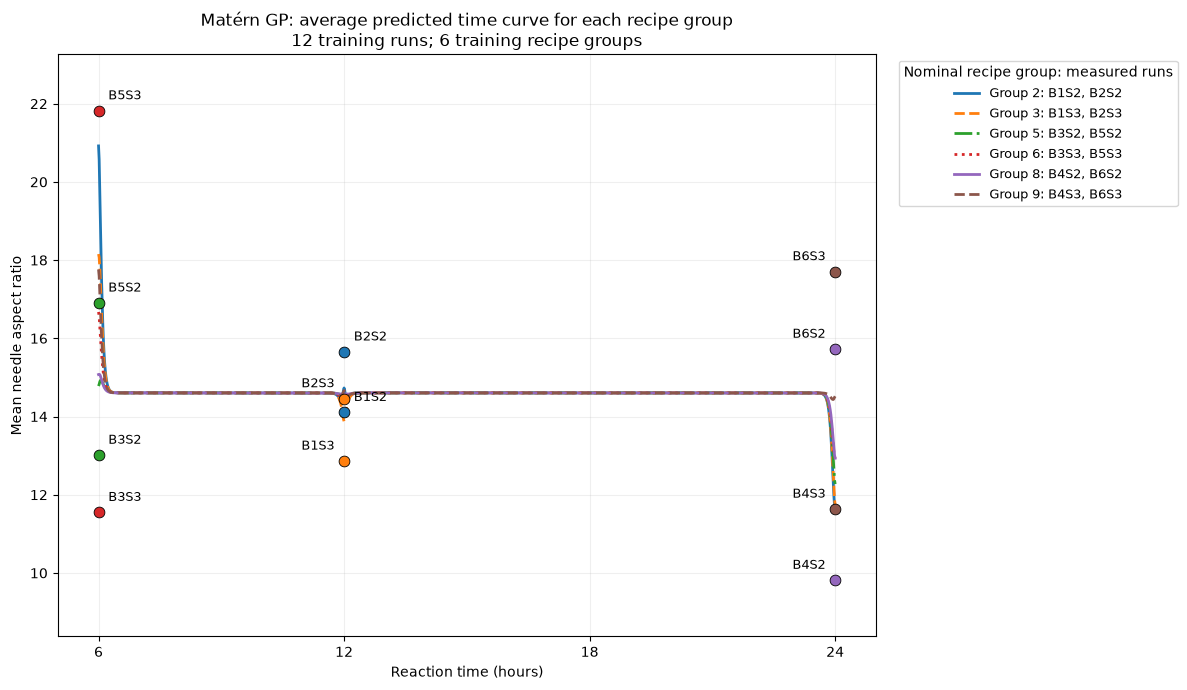

In [65]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Retrieve the fitted Matérn model from the same outer fold
outer_fold_to_plot = 3

matern_plot_model = (
    matern_searches[outer_fold_to_plot - 1]
    .best_estimator_
)

train_idx, _ = cv_splits[outer_fold_to_plot - 1]

X_subset = X.iloc[train_idx].copy()
y_subset = y.iloc[train_idx].copy()

# Retrieve recipe groups for these training observations
groups_subset = data.loc[
    X_subset.index,
    "recipe_group"
]

group_ids = sorted(groups_subset.unique())

# Use a fine grid to capture the model's narrow changes
# This grid includes 6, 12 and 24 hours exactly
time_grid = np.linspace(6, 24, 1201)

colours = plt.get_cmap("tab10").colors
line_styles = ["-", "--", "-.", ":"]

fig, ax = plt.subplots(figsize=(12, 7))

matern_group_curves = {}

# 2. Calculate one average predicted curve per recipe group
for i, group_id in enumerate(group_ids):

    group_indices = groups_subset.index[
        groups_subset == group_id
    ]

    run_curves = []

    # Predict a time curve using each run's recorded inputs
    for idx in group_indices:

        recipe = X_subset.loc[idx]

        curve_inputs = pd.DataFrame(
            [recipe.to_dict()] * len(time_grid)
        )

        curve_inputs["time_h"] = time_grid

        predicted_ar = matern_plot_model.predict(
            curve_inputs
        )

        run_curves.append(predicted_ar)

    # Average member predictions at each reaction time
    group_curve = np.mean(
        np.vstack(run_curves),
        axis=0
    )

    matern_group_curves[group_id] = group_curve

    sample_names = (
        data.loc[group_indices, "notes"]
        .dropna()
        .astype(str)
    )

    label = (
        f"Group {group_id}: "
        + ", ".join(sample_names)
    )

    colour = colours[i % len(colours)]

    # 3. Draw the group curve
    ax.plot(
        time_grid,
        group_curve,
        color=colour,
        linestyle=line_styles[i % len(line_styles)],
        linewidth=2,
        label=label
    )

    # Draw the individual measured observations
    ax.scatter(
        X_subset.loc[group_indices, "time_h"],
        y_subset.loc[group_indices],
        color=colour,
        edgecolors="black",
        linewidths=0.6,
        s=60,
        zorder=3
    )

    # Label each observation using the notes column
    for idx in group_indices:

        if pd.isna(data.loc[idx, "notes"]):
            continue

        reaction_time = X_subset.loc[idx, "time_h"]

        if reaction_time == time_grid.min():
            offset_x = 7
        elif reaction_time == time_grid.max():
            offset_x = -7
        else:
            offset_x = 7 if i == 0 else -7

        ax.annotate(
            str(data.loc[idx, "notes"]),
            xy=(reaction_time, y_subset.loc[idx]),
            xytext=(offset_x, 6),
            textcoords="offset points",
            ha="left" if offset_x > 0 else "right",
            va="bottom",
            fontsize=9
        )

# 4. Format the figure consistently with the RBF plot
ax.set_xlabel("Reaction time (hours)")
ax.set_ylabel("Mean needle aspect ratio")

ax.set_title(
    "Matérn GP: average predicted time curve for each recipe group\n"
    f"{len(X_subset)} training runs; "
    f"{len(group_ids)} training recipe groups"
)

ax.set_xlim(5, 25)
ax.set_xticks([6, 12, 18, 24])
ax.margins(y=0.12)
ax.grid(alpha=0.2)

ax.legend(
    title="Nominal recipe group: measured runs",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9,
    title_fontsize=10
)

fig.tight_layout()
plt.show()

c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\ethan\anaconda3\envs\dtu-ml\Li

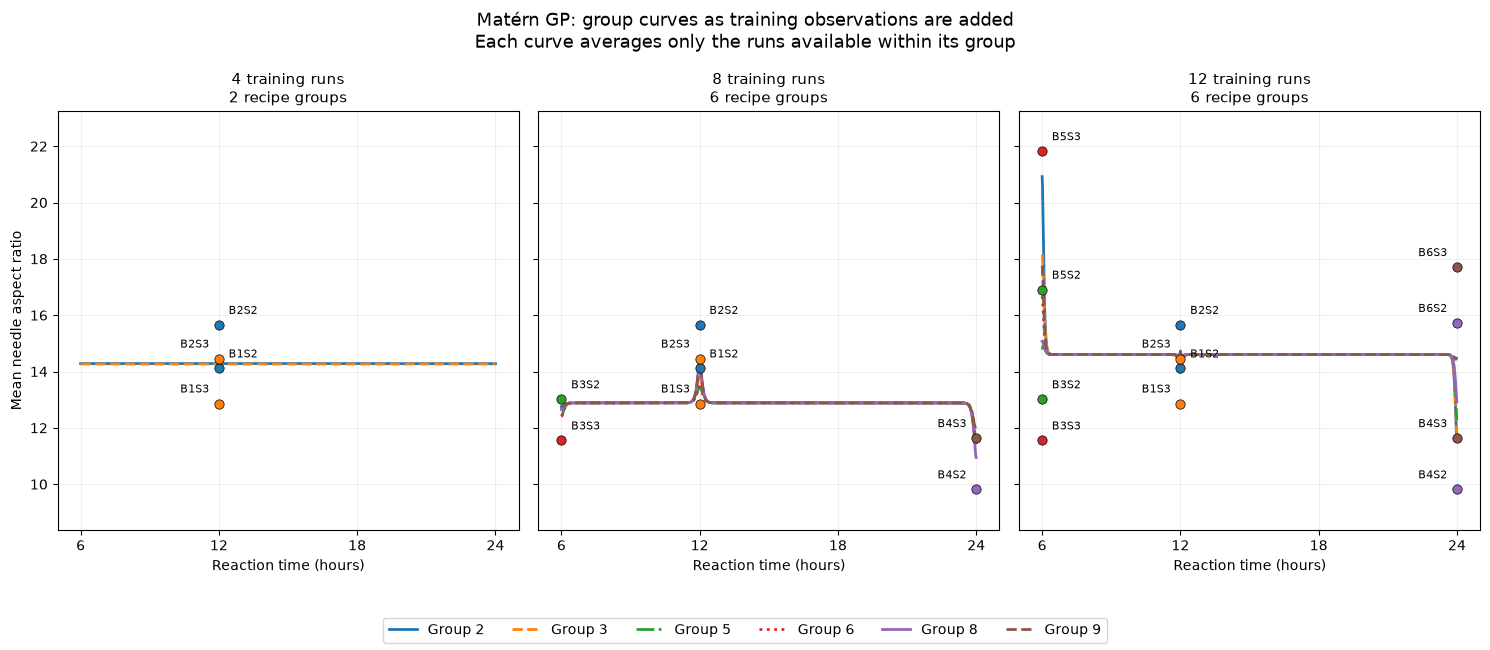

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

# 1. Select the same training pool and observation order as before
outer_fold_to_plot = 3
matern_observation_counts = [4, 8, 12]

train_idx, _ = cv_splits[outer_fold_to_plot - 1]

X_matern_pool = X.iloc[train_idx].copy()
y_matern_pool = y.iloc[train_idx].copy()

groups_matern_pool = data.loc[
    X_matern_pool.index,
    "recipe_group"
]

# Keep each group's colour and line style consistent across panels
group_ids = sorted(groups_matern_pool.unique())

palette = plt.get_cmap("tab10").colors
styles = ["-", "--", "-.", ":"]

group_colours = {
    g: palette[i]
    for i, g in enumerate(group_ids)
}

group_styles = {
    g: styles[i % len(styles)]
    for i, g in enumerate(group_ids)
}

time_grid = np.linspace(6, 24, 1201)

fig, axes = plt.subplots(
    1,
    len(matern_observation_counts),
    figsize=(15, 6.5),
    sharex=True,
    sharey=True
)

# Keep these separate from the earlier RBF models
matern_evolution_models = []
matern_evolution_group_curves = {}

# 2. Fit a fresh Matérn model at each stage
for ax, n_observations in zip(
    axes,
    matern_observation_counts
):

    X_subset = X_matern_pool.iloc[:n_observations]
    y_subset = y_matern_pool.iloc[:n_observations]

    stage_groups = groups_matern_pool.loc[
        X_subset.index
    ]

    stage_model = clone(matern_model)

    stage_model.set_params(
        gp__kernel=clone(matern_separate_kernel)
    )

    stage_model.fit(X_subset, y_subset)

    matern_evolution_models.append(stage_model)

    stage_curves = {}

    # 3. Average only the group members available at this stage
    for group_id in sorted(stage_groups.unique()):

        group_indices = stage_groups.index[
            stage_groups == group_id
        ]

        run_curves = []

        for idx in group_indices:

            recipe = X_subset.loc[idx]

            curve_inputs = pd.DataFrame(
                [recipe.to_dict()] * len(time_grid)
            )

            curve_inputs["time_h"] = time_grid

            run_curves.append(
                stage_model.predict(curve_inputs)
            )

        group_curve = np.mean(
            np.vstack(run_curves),
            axis=0
        )

        stage_curves[group_id] = group_curve
        colour = group_colours[group_id]

        ax.plot(
            time_grid,
            group_curve,
            color=colour,
            linestyle=group_styles[group_id],
            linewidth=2,
            label=f"Group {group_id}"
        )

        ax.scatter(
            X_subset.loc[group_indices, "time_h"],
            y_subset.loc[group_indices],
            color=colour,
            edgecolors="black",
            linewidths=0.5,
            s=45,
            zorder=3
        )

        # 4. Label observations available at this stage
        for idx in group_indices:

            if pd.isna(data.loc[idx, "notes"]):
                continue

            reaction_time = X_subset.loc[idx, "time_h"]

            if reaction_time == time_grid.min():
                offset_x = 7
            elif reaction_time == time_grid.max():
                offset_x = -7
            else:
                offset_x = (
                    7 if group_id == group_ids[0] else -7
                )

            ax.annotate(
                str(data.loc[idx, "notes"]),
                xy=(reaction_time, y_subset.loc[idx]),
                xytext=(offset_x, 6),
                textcoords="offset points",
                ha="left" if offset_x > 0 else "right",
                va="bottom",
                fontsize=8
            )

    matern_evolution_group_curves[
        n_observations
    ] = stage_curves

    ax.set_title(
        f"{n_observations} training runs\n"
        f"{stage_groups.nunique()} recipe groups",
        fontsize=11
    )

    ax.set_xlabel("Reaction time (hours)")
    ax.set_xlim(5, 25)
    ax.set_xticks([6, 12, 18, 24])
    ax.margins(y=0.12)
    ax.grid(alpha=0.2)

# 5. Add a shared title and legend
axes[0].set_ylabel("Mean needle aspect ratio")

fig.suptitle(
    "Matérn GP: group curves as training observations are added\n"
    "Each curve averages only the runs available within its group",
    fontsize=13
)

# The last panel contains all six training recipe groups
handles, labels = axes[-1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=6,
    fontsize=10
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

plt.show()

,OOF RMSE,OOF MAE,RMSE reduction vs baseline (%)
Model,,,
Mean baseline,3.0632,2.3618,0.0000
Random Forest,3.1112,2.4651,-1.5678
Matérn GP,3.4278,2.6754,-11.9034
RBF GP,3.0289,2.3680,1.1185


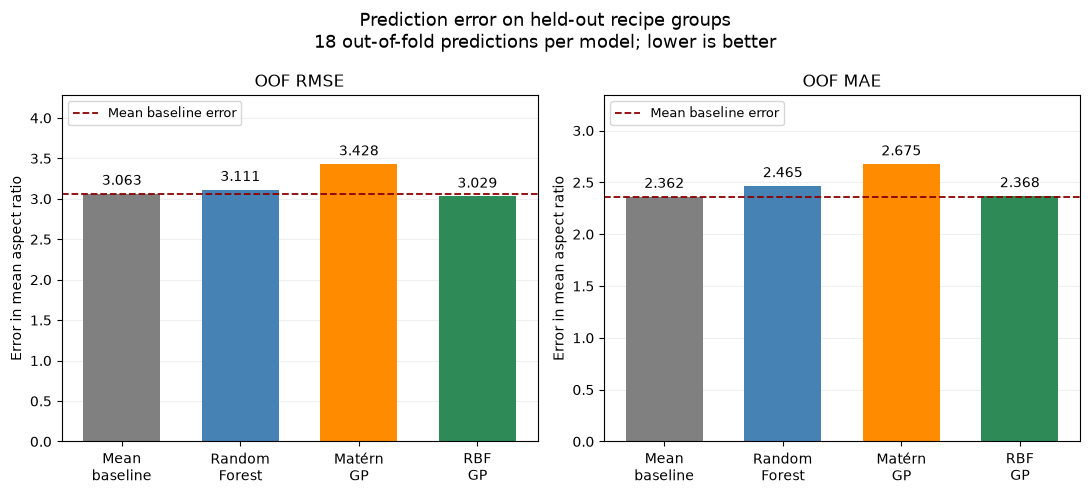

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Collect the existing out-of-fold predictions
# These arrays have the same row order as y
prediction_sets = {
    "Mean baseline": baseline_oof_predictions,
    "Random Forest": rf_oof_predictions,
    "Matérn GP": matern_oof_predictions,
    "RBF GP": rbf_oof_predictions
}

y_true = y.to_numpy(dtype=float)

comparison_rows = []

# 2. Calculate errors across all 18 held-out predictions
for model_name, predictions in prediction_sets.items():

    predictions = np.asarray(predictions, dtype=float)

    errors = predictions - y_true

    comparison_rows.append({
        "Model": model_name,
        "OOF RMSE": np.sqrt(np.mean(errors ** 2)),
        "OOF MAE": np.mean(np.abs(errors))
    })

oof_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Model")
)

# Positive reduction means lower RMSE than the baseline
baseline_rmse = oof_comparison.loc[
    "Mean baseline",
    "OOF RMSE"
]

oof_comparison["RMSE reduction vs baseline (%)"] = (
    100
    * (baseline_rmse - oof_comparison["OOF RMSE"])
    / baseline_rmse
)

display(oof_comparison.round(4))

# 3. Plot both metrics
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

x_positions = np.arange(len(oof_comparison))

tick_labels = [
    "Mean\nbaseline",
    "Random\nForest",
    "Matérn\nGP",
    "RBF\nGP"
]

colours = [
    "grey",
    "steelblue",
    "darkorange",
    "seagreen"
]

for ax, metric in zip(axes, ["OOF RMSE", "OOF MAE"]):

    values = oof_comparison[metric].to_numpy()

    bars = ax.bar(
        x_positions,
        values,
        color=colours,
        width=0.65
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=4
    )

    # Show the baseline error as a reference line
    ax.axhline(
        oof_comparison.loc["Mean baseline", metric],
        color="darkred",
        linestyle="--",
        linewidth=1.3,
        label="Mean baseline error"
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(tick_labels)

    ax.set_ylabel("Error in mean aspect ratio")
    ax.set_title(metric)

    # Start at zero so small differences are not exaggerated
    ax.set_ylim(0, values.max() * 1.25)

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper left", fontsize=9)

fig.suptitle(
    "Prediction error on held-out recipe groups\n"
    "18 out-of-fold predictions per model; lower is better",
    fontsize=13
)

fig.tight_layout()
plt.show()

In [68]:
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV

# 1. Create shared grouped folds for final hyperparameter selection
final_cv = GroupKFold(n_splits=3)

final_cv_splits = list(
    final_cv.split(X, y, groups)
)

# 2. Fit the final baseline on all available observations
final_baseline_model = DummyRegressor(
    strategy="mean"
)

final_baseline_model.fit(X, y)

# 3. Select one RF configuration using the existing parameter grid
final_rf_search = GridSearchCV(
    estimator=clone(rf_model),
    param_grid=rf_param_grid,
    scoring=selection_scoring,
    cv=final_cv_splits,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise"
)

final_rf_search.fit(X, y)

# refit=True has already fitted this model on all rows of X
final_rf_model = final_rf_search.best_estimator_

# 4. Display the selected settings and tuning score
print("Selected final RF hyperparameters:")

display(
    pd.DataFrame([final_rf_search.best_params_])
)

print(
    "Mean tuning-CV RMSE for the selected RF configuration: "
    f"{-final_rf_search.best_score_:.4f}"
)

print(
    f"Final RF fitted on {len(X)} runs "
    f"from {groups.nunique()} recipe groups."
)

print(
    "Final baseline prediction: "
    f"{final_baseline_model.constant_.item():.4f}"
)

Selected final RF hyperparameters:


,max_depth,max_features,min_samples_leaf
0,None,0.5,1


Mean tuning-CV RMSE for the selected RF configuration: 2.9427
Final RF fitted on 18 runs from 9 recipe groups.
Final baseline prediction: 14.9305


In [69]:
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

# 1. Compare the Matérn candidates using the shared final folds
final_matern_search = GridSearchCV(
    estimator=clone(matern_model),
    param_grid=matern_param_grid,
    scoring=selection_scoring,
    cv=final_cv_splits,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise"
)

final_matern_search.fit(X, y)

# 2. Retrieve the pipeline refitted on all 18 observations
final_matern_model = (
    final_matern_search.best_estimator_
)

# kernel_ contains the parameters learned during fitting
final_matern_gp = (
    final_matern_model.named_steps["gp"]
)

final_matern_kernel = final_matern_gp.kernel_

fitted_length_scales = np.atleast_1d(
    final_matern_kernel.k1.k2.length_scale
)

length_scale_setup = (
    "One shared length scale"
    if fitted_length_scales.size == 1
    else "Separate length scales for the inputs"
)

# 3. Display the selected structure and fitted kernel
print(
    "Selected Matérn structure:",
    length_scale_setup
)

print(
    "Mean selection-CV RMSE: "
    f"{-final_matern_search.best_score_:.4f}"
)

print("Final fitted kernel:")
print(final_matern_kernel)

print(
    f"Final Matérn GP fitted on {len(X)} runs "
    f"from {groups.nunique()} recipe groups."
)

Selected Matérn structure: One shared length scale
Mean selection-CV RMSE: 3.0244
Final fitted kernel:
1.02**2 * Matern(length_scale=0.01, nu=1.5) + WhiteKernel(noise_level=0.118)
Final Matérn GP fitted on 18 runs from 9 recipe groups.


c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [70]:
import numpy as np

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

# 1. Compare RBF candidates using the same final tuning folds
final_rbf_search = GridSearchCV(
    estimator=clone(rbf_model),
    param_grid=rbf_param_grid,
    scoring=selection_scoring,
    cv=final_cv_splits,
    refit=True,
    return_train_score=True,
    n_jobs=-1,
    error_score="raise"
)

final_rbf_search.fit(X, y)

# 2. Retrieve the selected pipeline refitted on all observations
final_rbf_model = final_rbf_search.best_estimator_

final_rbf_gp = final_rbf_model.named_steps["gp"]
final_rbf_kernel = final_rbf_gp.kernel_

rbf_length_scales = np.atleast_1d(
    final_rbf_kernel.k1.k2.length_scale
)

rbf_length_scale_setup = (
    "One shared length scale"
    if rbf_length_scales.size == 1
    else "Separate length scales for the inputs"
)

# 3. Display the selected structure and learned kernel
print(
    "Selected RBF structure:",
    rbf_length_scale_setup
)

print(
    "Mean selection-CV RMSE: "
    f"{-final_rbf_search.best_score_:.4f}"
)

print("Final fitted kernel:")
print(final_rbf_kernel)

print(
    f"Final RBF GP fitted on {len(X)} runs "
    f"from {groups.nunique()} recipe groups."
)

# 4. Collect all four fitted models for the next prediction steps
final_models = {
    "Mean baseline": final_baseline_model,
    "Random Forest": final_rf_model,
    "Matérn GP": final_matern_model,
    "RBF GP": final_rbf_model
}

Selected RBF structure: One shared length scale
Mean selection-CV RMSE: 3.0244
Final fitted kernel:
1.03**2 * RBF(length_scale=0.01) + WhiteKernel(noise_level=0.122)
Final RBF GP fitted on 18 runs from 9 recipe groups.


c:\Users\ethan\anaconda3\envs\dtu-ml\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,Mean baseline,Random Forest,Matérn GP,RBF GP
0,6,0.1403,1.0249,55,14.9305,19.3349,21.1161,21.1023
1,9,0.1403,1.0249,55,14.9305,19.3349,14.9305,14.9305
2,12,0.1403,1.0249,55,14.9305,17.3991,14.9305,14.9305
3,18,0.1403,1.0249,55,14.9305,17.3995,14.9305,14.9305
4,24,0.1403,1.0249,55,14.9305,16.4811,14.9305,14.9305


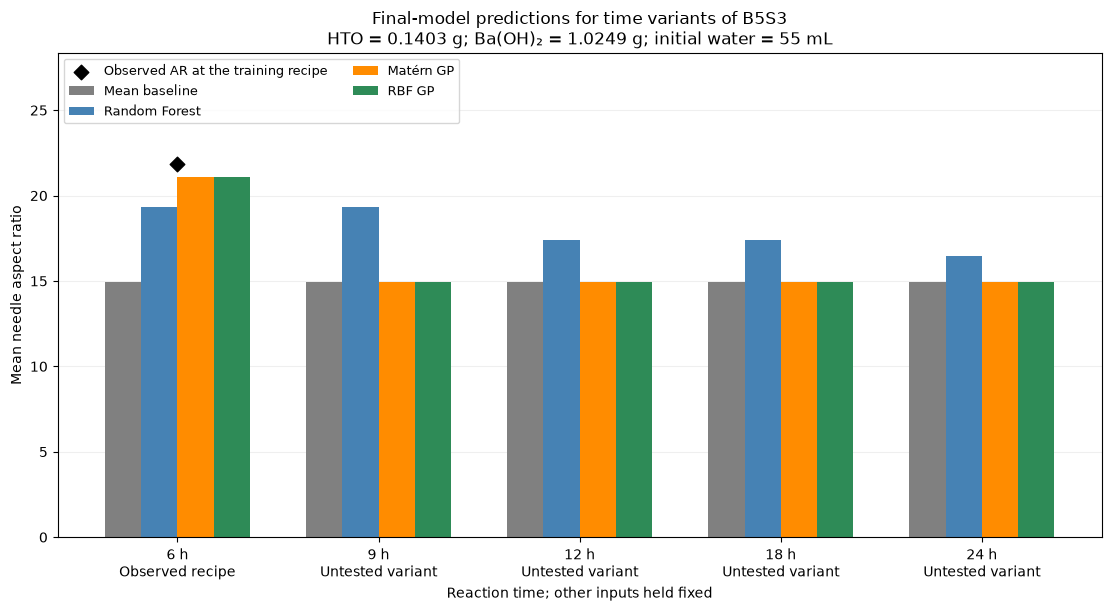

In [71]:
# Using the selected fitted models for baseline, RF, Matern and RBF, we can compare the predictions for similar recipes with changes in one variable (e.g. reaction time)

# 1. Choose the reference recipe and reaction times to compare
reference_sample = "B5S3"
candidate_times = [6, 9, 12, 18, 24]

# 2. Find the reference sample using the notes column
reference_rows = data.index[
    data["notes"].astype(str).str.strip().eq(reference_sample)
]

if len(reference_rows) != 1:
    raise ValueError(
        "The reference sample must match exactly one row."
    )

reference_index = reference_rows[0]
reference_inputs = X.loc[[reference_index]].copy()

# 3. Copy the reference inputs, changing only reaction time
candidate_inputs = pd.concat(
    [reference_inputs] * len(candidate_times),
    ignore_index=True
)

candidate_inputs["time_h"] = candidate_times

# 4. Obtain predictions from all four final fitted models
candidate_predictions = pd.DataFrame(
    index=candidate_inputs.index
)

for model_name, model in final_models.items():
    candidate_predictions[model_name] = model.predict(
        candidate_inputs
    )

# Combine the inputs and predictions into one table
candidate_comparison = pd.concat(
    [candidate_inputs, candidate_predictions],
    axis=1
)

display(candidate_comparison.round(4))

# 5. Plot the predictions side by side
x_positions = np.arange(len(candidate_times))
bar_width = 0.18

colours = [
    "grey",
    "steelblue",
    "darkorange",
    "seagreen"
]

fig, ax = plt.subplots(
    figsize=(11, 6),
    layout="constrained"
)

for j, model_name in enumerate(final_models):
    ax.bar(
        x_positions + (j - 1.5) * bar_width,
        candidate_predictions[model_name],
        width=bar_width,
        color=colours[j],
        label=model_name
    )

# 6. Mark the measured AR at the original reference condition
reference_time = reference_inputs["time_h"].iloc[0]

reference_positions = np.flatnonzero(
    np.asarray(candidate_times) == reference_time
)

ax.scatter(
    reference_positions,
    np.repeat(
        y.loc[reference_index],
        len(reference_positions)
    ),
    color="black",
    marker="D",
    s=55,
    zorder=5,
    label="Observed AR at the training recipe"
)

# 7. Format the plot
ax.set_xticks(x_positions)

ax.set_xticklabels([
    f"{time} h\n" + (
        "Observed recipe"
        if time == reference_time
        else "Untested variant"
    )
    for time in candidate_times
])

ax.set_xlabel("Reaction time; other inputs held fixed")
ax.set_ylabel("Mean needle aspect ratio")

ax.set_title(
    f"Final-model predictions for time variants of {reference_sample}\n"
    f"HTO = {reference_inputs['hto_mass_g'].iloc[0]:.4f} g; "
    f"Ba(OH)₂ = {reference_inputs['baoh_mass_g'].iloc[0]:.4f} g; "
    f"initial water = "
    f"{reference_inputs['water_initial_ml'].iloc[0]:g} mL"
)

ax.set_ylim(
    0,
    1.3 * max(
        candidate_predictions.to_numpy().max(),
        y.loc[reference_index]
    )
)

ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.show()

time_h  predicted_mean_ar  function_std  observation_std
model     candidate                                                          
Matérn GP 0               6             21.116         0.977            1.421
          1               9             14.930         3.059            3.228
          2              12             14.930         3.059            3.228
          3              18             14.930         3.059            3.228
          4              24             14.930         3.059            3.228
RBF GP    0               6             21.102         0.993            1.444
          1               9             14.930         3.074            3.248
          2              12             14.930         3.074            3.248
          3              18             14.930         3.074            3.248
          4              24             14.930         3.074            3.248

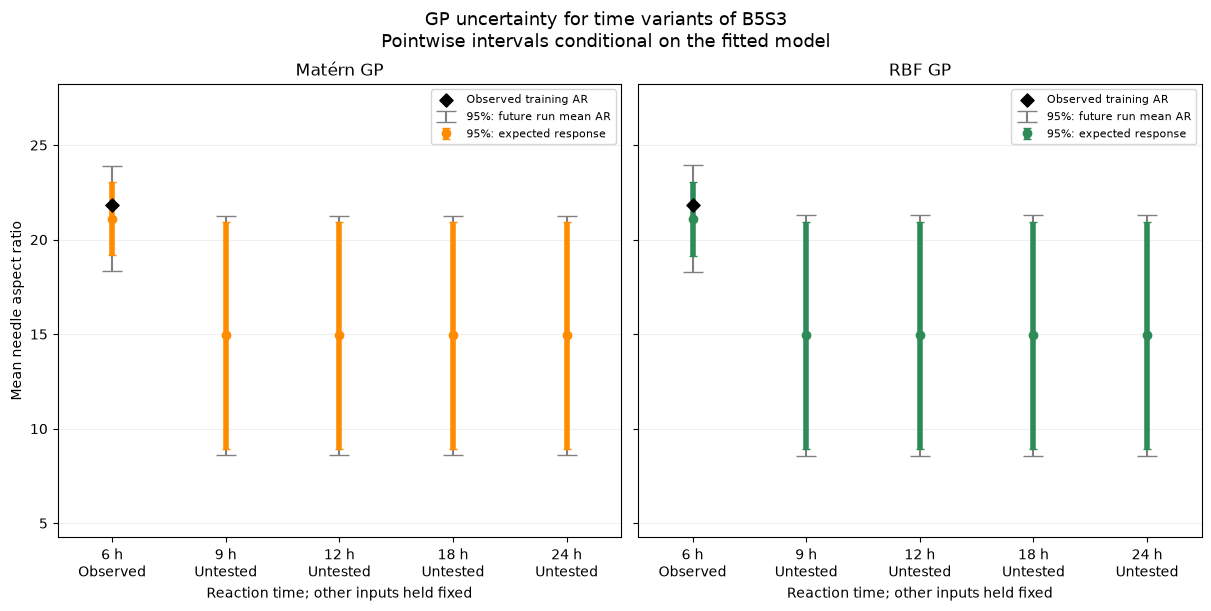

In [72]:
# add uncertainty intervals to the GP predictions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Use the final GP models and the previous candidate inputs
gp_models = {
    "Matérn GP": final_matern_model,
    "RBF GP": final_rbf_model
}

gp_candidate_results = {}

# Both final models used normalize_y=True and all values in y
target_variance = y.var(ddof=0)

# 2. Calculate both kinds of predictive uncertainty
for model_name, model in gp_models.items():

    prediction_mean, observation_std = model.predict(
        candidate_inputs,
        return_std=True
    )

    fitted_gp = model.named_steps["gp"]

    # Our kernel is:
    # Constant * (Matérn or RBF) + WhiteKernel
    noise_variance = (
        fitted_gp.kernel_.k2.noise_level
        * target_variance
    )

    function_variance = (
        observation_std ** 2 - noise_variance
    )

    if np.any(function_variance < -1e-10):
        raise ValueError(
            "Check the kernel structure and target scaling."
        )

    function_std = np.sqrt(
        np.maximum(function_variance, 0.0)
    )

    gp_candidate_results[model_name] = pd.DataFrame({
        "time_h": candidate_inputs["time_h"].to_numpy(),
        "predicted_mean_ar": prediction_mean,
        "function_std": function_std,
        "observation_std": observation_std
    })

# 3. Display the results from both models
uncertainty_table = pd.concat(
    gp_candidate_results,
    names=["model", "candidate"]
)

display(uncertainty_table.round(3))

# 4. Plot intervals for each candidate condition
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharey=True,
    layout="constrained"
)

x_positions = np.arange(len(candidate_inputs))

reference_time = reference_inputs["time_h"].iloc[0]

reference_positions = np.flatnonzero(
    candidate_inputs["time_h"].to_numpy() == reference_time
)

for ax, (model_name, results), colour in zip(
    axes,
    gp_candidate_results.items(),
    ["darkorange", "seagreen"]
):

    # Wider grey interval: a future run's measured mean AR
    ax.errorbar(
        x_positions,
        results["predicted_mean_ar"],
        yerr=1.96 * results["observation_std"],
        fmt="none",
        ecolor="grey",
        elinewidth=1.5,
        capsize=7,
        label="95%: future run mean AR"
    )

    # Coloured interval: the underlying expected response
    ax.errorbar(
        x_positions,
        results["predicted_mean_ar"],
        yerr=1.96 * results["function_std"],
        fmt="o",
        color=colour,
        elinewidth=4,
        capsize=3,
        label="95%: expected response"
    )

    # Show the recorded result at the original reference recipe
    ax.scatter(
        reference_positions,
        np.repeat(
            y.loc[reference_index],
            len(reference_positions)
        ),
        color="black",
        marker="D",
        s=45,
        zorder=5,
        label="Observed training AR"
    )

    ax.set_xticks(x_positions)

    ax.set_xticklabels([
        f"{time:g} h\n" + (
            "Observed"
            if time == reference_time
            else "Untested"
        )
        for time in candidate_inputs["time_h"]
    ])

    ax.set_title(model_name)
    ax.set_xlabel("Reaction time; other inputs held fixed")
    ax.margins(x=0.12, y=0.28)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper right", fontsize=8)

axes[0].set_ylabel("Mean needle aspect ratio")

fig.suptitle(
    f"GP uncertainty for time variants of {reference_sample}\n"
    "Pointwise intervals conditional on the fitted model",
    fontsize=13
)

plt.show()

| Quantity | What it describes |
|---|---|
| **Function uncertainty** | Uncertainty about the underlying expected mean AR at a recipe. |
| **Observation uncertainty** | Uncertainty about the measured mean AR from a **new synthesis run** at that recipe, including experimental variation represented by the model’s noise term. |

time_h  predicted_mean_ar  function_std  \
model     candidate                                            
Matérn GP 0               6             21.116         0.977   
          1               9             14.930         3.059   
          2              12             14.930         3.059   
          3              18             14.930         3.059   
          4              24             14.930         3.059   
RBF GP    0               6             21.102         0.993   
          1               9             14.930         3.074   
          2              12             14.930         3.074   
          3              18             14.930         3.074   
          4              24             14.930         3.074   

                     uncertainty_bonus  ucb_score  previously_tested  
model     candidate                                                   
Matérn GP 0                      1.954     23.071               True  
          1                      6.117     21.048              False  
          2                      6.117     21.048              False  
          3                      6.117     21.048              False  
          4                      6.117     21.048              False  
RBF GP    0                      1.985     23.087               True  
          1                      6.147     21.078              False  
          2                      6.147     21.078              False  
          3                      6.147     21.078              False  
          4                      6.147     21.078              False

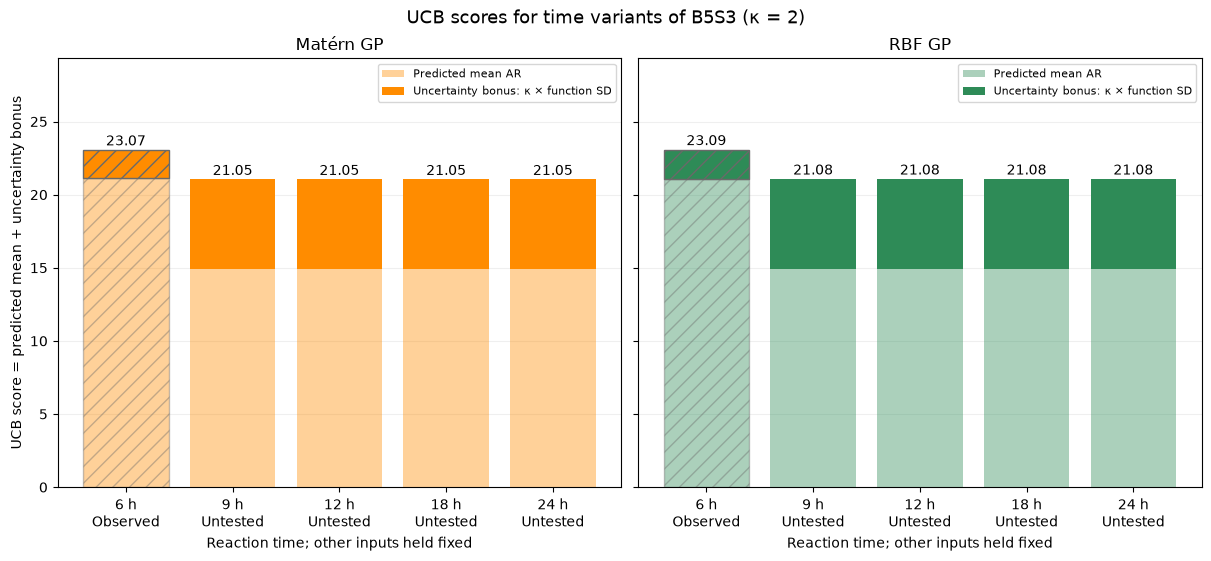

In [73]:
# Using the predicted mean and function uncertainty together to calculate an acquisition score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Choose how strongly uncertainty contributes to the score
kappa = 2.0

if kappa < 0:
    raise ValueError("kappa must be non-negative.")

# 2. Identify candidates that exactly match recorded model inputs
previously_tested = np.array([
    X.eq(row, axis="columns").all(axis=1).any()
    for _, row in candidate_inputs.iterrows()
])

# 3. Calculate UCB without changing either fitted GP
ucb_results = {}

for model_name, results in gp_candidate_results.items():

    scores = results[
        ["time_h", "predicted_mean_ar", "function_std"]
    ].copy()

    scores["uncertainty_bonus"] = (
        kappa * scores["function_std"]
    )

    scores["ucb_score"] = (
        scores["predicted_mean_ar"]
        + scores["uncertainty_bonus"]
    )

    scores["previously_tested"] = previously_tested

    ucb_results[model_name] = scores

ucb_table = pd.concat(
    ucb_results,
    names=["model", "candidate"]
)

display(ucb_table.round(3))

# 4. Plot the two contributions to each UCB score
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.5),
    sharey=True,
    layout="constrained"
)

x_positions = np.arange(len(candidate_inputs))

for ax, (model_name, scores), colour in zip(
    axes,
    ucb_results.items(),
    ["darkorange", "seagreen"]
):

    mean_bars = ax.bar(
        x_positions,
        scores["predicted_mean_ar"],
        color=colour,
        alpha=0.4,
        label="Predicted mean AR"
    )

    bonus_bars = ax.bar(
        x_positions,
        scores["uncertainty_bonus"],
        bottom=scores["predicted_mean_ar"],
        color=colour,
        label="Uncertainty bonus: κ × function SD"
    )

    ax.legend(loc="upper right", fontsize=8)

    # Hatching identifies an already observed input combination
    for i in np.flatnonzero(previously_tested):
        for bars in [mean_bars, bonus_bars]:
            bars[i].set_hatch("//")
            bars[i].set_edgecolor("dimgray")

    # Label each bar with its total UCB score
    for i, score in enumerate(scores["ucb_score"]):
        ax.text(
            i,
            score + 0.3,
            f"{score:.2f}",
            ha="center"
        )

    ax.set_xticks(x_positions)

    ax.set_xticklabels([
        f"{time:g} h\n" + (
            "Observed" if seen else "Untested"
        )
        for time, seen in zip(
            scores["time_h"],
            previously_tested
        )
    ])

    ax.set_title(model_name)
    ax.set_xlabel("Reaction time; other inputs held fixed")
    ax.set_ylim(0, 1.27 * scores["ucb_score"].max())
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel(
    "UCB score = predicted mean + uncertainty bonus"
)

fig.suptitle(
    f"UCB scores for time variants of {reference_sample} "
    f"(κ = {kappa:g})",
    fontsize=13
)

plt.show()

'kappa' is an acquisition setting. It controls how we use the model’s predictions to compare experiments.

| Consideration | Meaning | UCB component |
|---|---|---|
| **Exploitation** | Investigate conditions already predicted to perform well. | Predicted mean, \(\mu(x)\) |
| **Exploration** | Investigate uncertain conditions that might perform better than currently predicted. | Uncertainty bonus, \(\kappa\sigma_f(x)\) |

- With kappa = 0, the score uses only the predicted mean.
- Increasing kappa gives uncertain candidates a larger bonus.
- Here, kappa = 2 means adding twice the function SD.

Changing kappa does not retrain the GP or change its predictions. It **changes the acquisition scores** and potentially the preferred experiment.

In [74]:
# define the candidate search space: the set of processing conditions that the models will evaluate

import pandas as pd
from itertools import product
from IPython.display import display

# 1. Editable input values for the initial candidate grid
search_values = {
    "time_h": [6, 9, 12, 18, 24],
    "hto_mass_g": [0.1400],
    "baoh_mass_g": [0.7712, 1.0253, 1.5428],
    "water_initial_ml": [30, 40, 50, 55]
}

# 2. Conditions held at the values used in the training experiments
fixed_conditions = {
    "temperature_c": 210,
    "water_rinse_ml": 10
}

# 3. Generate every combination of the chosen model-input values
candidate_grid = pd.DataFrame(
    product(*search_values.values()),
    columns=search_values.keys()
)

# Preserve the exact feature order used during model fitting
candidate_grid = candidate_grid.loc[:, X.columns]

# 4. Add the fixed conditions to a table for inspecting the recipes
candidate_recipes = candidate_grid.copy()

for column, value in fixed_conditions.items():
    candidate_recipes[column] = value

# 5. Inspect the candidate count and the first twelve combinations
print(f"Candidate input combinations: {len(candidate_grid)}")
print("First 12 candidate combinations:")

display(candidate_recipes.head(12).round(4))

Candidate input combinations: 60
First 12 candidate combinations:


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,temperature_c,water_rinse_ml
0,6,0.14,0.7712,30,210,10
1,6,0.14,0.7712,40,210,10
2,6,0.14,0.7712,50,210,10
3,6,0.14,0.7712,55,210,10
4,6,0.14,1.0253,30,210,10
5,6,0.14,1.0253,40,210,10
6,6,0.14,1.0253,50,210,10
7,6,0.14,1.0253,55,210,10
8,6,0.14,1.5428,30,210,10
9,6,0.14,1.5428,40,210,10


Matérn GP: 60 candidates scored; 1 at the highest score within tolerance.


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,predicted_mean_ar,function_std,ucb_score,exact_recorded_match
10,6,0.14,1.5428,50,15.1641,3.0564,21.2768,False


RBF GP: 60 candidates scored; 1 at the highest score within tolerance.


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,predicted_mean_ar,function_std,ucb_score,exact_recorded_match
10,6,0.14,1.5428,50,15.0324,3.0732,21.1788,False


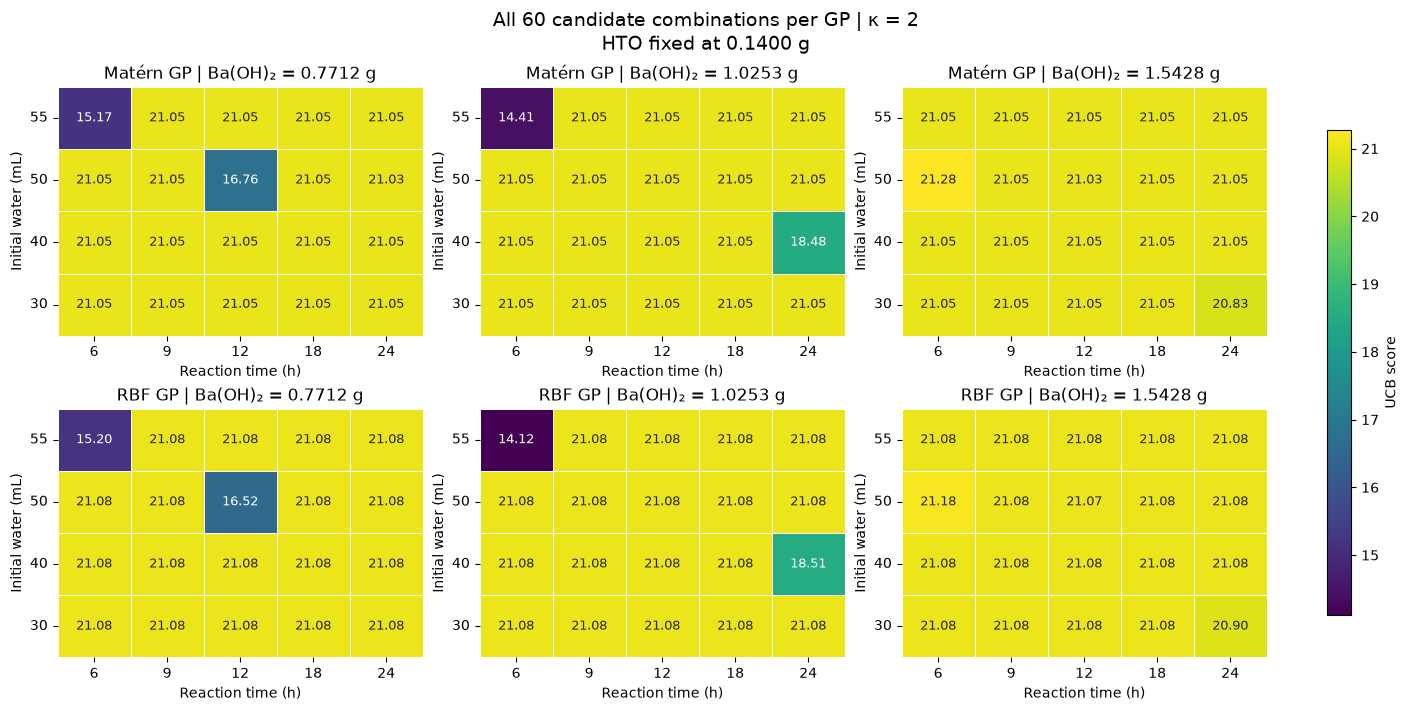

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# 1. Flag exact matches to the four recorded model inputs
exact_matches = np.array([
    X.eq(row, axis="columns").all(axis=1).any()
    for _, row in candidate_grid.iterrows()
])

# 2. Score the same grid with both final GPs
grid_results = {}

target_variance = y.var(ddof=0)
score_tolerance = 1e-6

for model_name, model in gp_models.items():

    prediction_mean, observation_std = model.predict(
        candidate_grid,
        return_std=True
    )

    fitted_gp = model.named_steps["gp"]

    noise_variance = (
        fitted_gp.kernel_.k2.noise_level
        * target_variance
    )

    function_variance = (
        observation_std ** 2 - noise_variance
    )

    if np.any(function_variance < -1e-10):
        raise ValueError(
            "Check the kernel structure and target scaling."
        )

    function_std = np.sqrt(
        np.maximum(function_variance, 0.0)
    )

    scores = candidate_grid.copy()

    scores["predicted_mean_ar"] = prediction_mean
    scores["function_std"] = function_std

    scores["ucb_score"] = (
        prediction_mean + kappa * function_std
    )

    scores["exact_recorded_match"] = exact_matches

    grid_results[model_name] = scores

    # Retain all numerical ties at the highest score
    top_candidates = scores.loc[
        np.isclose(
            scores["ucb_score"],
            scores["ucb_score"].max(),
            rtol=0,
            atol=score_tolerance
        )
    ]

    print(
        f"{model_name}: {len(scores)} candidates scored; "
        f"{len(top_candidates)} at the highest score "
        "within tolerance."
    )

    display(top_candidates.round(4))

# 3. Arrange the UCB scores by time, water and Ba(OH)₂ mass
# This plot uses the single HTO mass defined in the previous cell
mass_levels = sorted(
    candidate_grid["baoh_mass_g"].unique()
)

vmin = min(
    scores["ucb_score"].min()
    for scores in grid_results.values()
)

vmax = max(
    scores["ucb_score"].max()
    for scores in grid_results.values()
)

fig, axes = plt.subplots(
    2,
    len(mass_levels),
    figsize=(14, 7),
    squeeze=False,
    layout="constrained"
)

for row, (model_name, scores) in enumerate(
    grid_results.items()
):
    for column, mass in enumerate(mass_levels):

        score_matrix = (
            scores.loc[scores["baoh_mass_g"] == mass]
            .pivot(
                index="water_initial_ml",
                columns="time_h",
                values="ucb_score"
            )
            .sort_index(ascending=False)
        )

        ax = axes[row, column]

        sns.heatmap(
            score_matrix,
            ax=ax,
            annot=True,
            fmt=".2f",
            annot_kws={"fontsize": 9},
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            linewidths=0.5,
            cbar=False
        )

        ax.set_title(
            f"{model_name} | Ba(OH)₂ = {mass:.4f} g"
        )

        ax.set_xlabel("Reaction time (h)")
        ax.set_ylabel("Initial water (mL)")
        ax.tick_params(axis="y", rotation=0)

# Use one colour scale for all panels
fig.colorbar(
    axes[0, 0].collections[0],
    ax=axes.ravel().tolist(),
    label="UCB score",
    shrink=0.85
)

fig.suptitle(
    f"All {len(candidate_grid)} candidate combinations "
    f"per GP | κ = {kappa:g}\n"
    f"HTO fixed at "
    f"{candidate_grid['hto_mass_g'].iloc[0]:.4f} g",
    fontsize=14
)

plt.show()

In [76]:
# Screen for possible repeats of previously tested recipes in the candidate grid

import pandas as pd
from IPython.display import display

# 1. Editable similarity-screening tolerances
# Values use the same units as their corresponding input columns
comparison_tolerances = pd.Series({
    "time_h": 0.0,
    "hto_mass_g": 0.0005,
    "baoh_mass_g": 0.0010,
    "water_initial_ml": 0.0
})

# 2. Align the run labels with the rows used for model training
run_metadata = data.loc[
    X.index,
    ["recipe_group", "notes"]
]

match_records = []

# 3. Compare every candidate against each recorded run
for candidate_id, candidate in candidate_grid.iterrows():

    differences = X.sub(
        candidate,
        axis="columns"
    ).abs()

    # Tiny addition protects comparisons at floating-point boundaries
    within_tolerance = differences.le(
        comparison_tolerances + 1e-12,
        axis="columns"
    ).all(axis=1)

    matched_runs = run_metadata.loc[within_tolerance]

    match_records.append({
        "candidate_id": candidate_id,

        "near_existing_run": bool(
            within_tolerance.any()
        ),

        "matched_recipe_groups": ", ".join(
            str(group)
            for group in sorted(
                matched_runs["recipe_group"]
                .dropna()
                .unique()
            )
        ),

        "matched_samples": ", ".join(
            matched_runs["notes"]
            .dropna()
            .astype(str)
        )
    })

# 4. Attach the screening results to the candidate tables
candidate_matches = (
    pd.DataFrame(match_records)
    .set_index("candidate_id")
)

candidate_review = candidate_grid.join(
    candidate_matches
)

reviewed_grid_results = {}

for model_name, scores in grid_results.items():
    reviewed_grid_results[model_name] = scores.join(
        candidate_matches
    )

# 5. Display candidates that are close to recorded experiments
near_existing = candidate_review["near_existing_run"]

print(
    "Candidates close to recorded runs: "
    f"{near_existing.sum()}"
)

print(
    "Candidates with no close match: "
    f"{(~near_existing).sum()}"
)

display(
    candidate_review.loc[near_existing]
    .drop(columns="near_existing_run")
    .round(4)
)

Candidates close to recorded runs: 9
Candidates with no close match: 51


,time_h,hto_mass_g,baoh_mass_g,water_initial_ml,matched_recipe_groups,matched_samples
3,6,0.14,0.7712,55,5,"B3S2, B5S2"
7,6,0.14,1.0253,55,6,"B3S3, B5S3"
10,6,0.14,1.5428,50,4,"B3S1, B5S1"
26,12,0.14,0.7712,50,1,"B1S1, B2S1"
30,12,0.14,1.0253,50,2,"B1S2, B2S2"
34,12,0.14,1.5428,50,3,"B1S3, B2S3"
50,24,0.14,0.7712,50,9,B4S3
53,24,0.14,1.0253,40,7,"B4S1, B6S1"
56,24,0.14,1.5428,30,8,"B4S2, B6S2"


Candidate 10 is the highest-UCB candidate from both models. Its proximity to B3S1 and B5S1 means we should consider it a possible repeat of recipe group 4, rather than treating it as discovery of a substantially different recipe.

Also, candidate 50 matches B4S3 only, although B6S3 belongs to the same recipe group. B6S3’s recorded HTO mass is 0.1098 g, which falls outside the tolerance. Comparing individual runs preserves this distinction.

Finally, “no close match” means only that none of the recorded rows passes this particular screening rule. It does not establish that a candidate is feasible, substantially novel or likely to perform well.

Next, we’ll check whether the GPs can meaningfully distinguish the 51 candidates without a close match, before choosing any experiments.

In [77]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Keep a separate view of candidates with no close recorded match
unmatched_grid_results = {}
diagnostic_rows = []

for model_name, scores in reviewed_grid_results.items():

    unmatched = scores.loc[
        ~scores["near_existing_run"]
    ].copy()

    unmatched_grid_results[model_name] = unmatched

    if unmatched.empty:
        print(
            f"{model_name}: no candidates pass this screen."
        )
        continue

    # 2. Count candidates numerically tied with the highest UCB
    highest_ucb = unmatched["ucb_score"].max()

    tied_at_top = np.isclose(
        unmatched["ucb_score"],
        highest_ucb,
        rtol=0,
        atol=score_tolerance
    )

    print(
        f"{model_name}: {len(unmatched)} candidates; "
        f"{tied_at_top.sum()} tied at the highest UCB "
        f"within tolerance {score_tolerance:g}."
    )

    # 3. Check how much each quantity varies across candidates
    for quantity in [
        "predicted_mean_ar",
        "function_std",
        "ucb_score"
    ]:

        values = unmatched[quantity]

        diagnostic_rows.append({
            "model": model_name,
            "quantity": quantity,
            "minimum": values.min(),
            "maximum": values.max(),
            "range": values.max() - values.min()
        })

# 4. Display the diagnostic table
ranking_diagnostic = pd.DataFrame(
    diagnostic_rows,
    columns=[
        "model",
        "quantity",
        "minimum",
        "maximum",
        "range"
    ]
).set_index(["model", "quantity"])

display(ranking_diagnostic.round(6))

Matérn GP: 51 candidates; 51 tied at the highest UCB within tolerance 1e-06.
RBF GP: 51 candidates; 51 tied at the highest UCB within tolerance 1e-06.


minimum    maximum  range
model     quantity                                      
Matérn GP predicted_mean_ar  14.930458  14.930458    0.0
          function_std        3.058735   3.058735    0.0
          ucb_score          21.047928  21.047928    0.0
RBF GP    predicted_mean_ar  14.930458  14.930458    0.0
          function_std        3.073583   3.073583    0.0
          ucb_score          21.077625  21.077625    0.0

Increasing kappa would raise all 51 scores by the same amount. Decreasing it would lower them together.

What this means for our next step

**The current models have not provided a useful UCB ranking among these candidates**. This does not establish that the recipes perform equally, or that BO cannot help the project.

It tells us to examine how the fitted models interpret differences between experimental inputs before using their rankings to choose experiments.

Next, we’ll convert the fitted length scales into hours, grams and millilitres. That will make it much clearer what the GPs currently consider a “small” change in a recipe.

In [78]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. State the original units of the four model inputs
input_units = {
    "time_h": "h",
    "hto_mass_g": "g",
    "baoh_mass_g": "g",
    "water_initial_ml": "mL"
}

length_scale_rows = []

# 2. Read the scaler and learned kernel from each fitted pipeline
for model_name, model in gp_models.items():

    fitted_scaler = model.named_steps["scale"]
    fitted_gp = model.named_steps["gp"]

    response_kernel = fitted_gp.kernel_.k1.k2

    scaled_lengths = np.atleast_1d(
        response_kernel.length_scale
    )

    # A shared length scale applies to every standardized input
    if scaled_lengths.size == 1:
        scaled_lengths = np.repeat(
            scaled_lengths,
            len(fitted_scaler.scale_)
        )

    # 3. Convert length scales to the original input units
    physical_lengths = (
        scaled_lengths * fitted_scaler.scale_
    )

    for feature, scaled_length, input_scale, physical_length in zip(
        fitted_scaler.feature_names_in_,
        scaled_lengths,
        fitted_scaler.scale_,
        physical_lengths
    ):

        length_scale_rows.append({
            "model": model_name,
            "input": feature,
            "unit": input_units[feature],
            "standardized_length_scale": scaled_length,
            "training_input_sd": input_scale,
            "physical_length_scale": physical_length
        })

# 4. Display the converted length scales
length_scale_table = pd.DataFrame(
    length_scale_rows
).set_index(["model", "input"])

display(length_scale_table.round(8))

unit  standardized_length_scale  training_input_sd  \
model     input                                                                 
Matérn GP time_h              h                       0.01           7.483315   
          hto_mass_g          g                       0.01           0.006957   
          baoh_mass_g         g                       0.01           0.321010   
          water_initial_ml   mL                       0.01           7.494854   
RBF GP    time_h              h                       0.01           7.483315   
          hto_mass_g          g                       0.01           0.006957   
          baoh_mass_g         g                       0.01           0.321010   
          water_initial_ml   mL                       0.01           7.494854   

                            physical_length_scale  
model     input                                    
Matérn GP time_h                         0.074833  
          hto_mass_g                     0.000070  
          baoh_mass_g                    0.003210  
          water_initial_ml               0.074949  
RBF GP    time_h                         0.074833  
          hto_mass_g                     0.000070  
          baoh_mass_g                    0.003210  
          water_initial_ml               0.074949

In [79]:
import pandas as pd
from IPython.display import display

# 1. Use the recorded rows included in model training
training_rows = data.loc[X.index].copy()

pair_rows = []

# 2. Compare the two runs in each recipe group
for group_id, rows in training_rows.groupby(
    "recipe_group",
    sort=True
):

    if len(rows) != 2:
        raise ValueError(
            "This paired comparison expects two runs "
            "per recipe group."
        )

    # First and second refer to their order in the data table
    first = rows.iloc[0]
    second = rows.iloc[1]

    pair_rows.append({
        "recipe_group": group_id,

        "samples": (
            f"{first['notes']} → {second['notes']}"
        ),

        "time_difference_h": abs(
            second["time_h"] - first["time_h"]
        ),

        "hto_difference_mg": 1000 * abs(
            second["hto_mass_g"] - first["hto_mass_g"]
        ),

        "baoh_difference_mg": 1000 * abs(
            second["baoh_mass_g"] - first["baoh_mass_g"]
        ),

        "water_difference_ml": abs(
            second["water_initial_ml"]
            - first["water_initial_ml"]
        ),

        "first_ar": first["aspect_ratio"],
        "second_ar": second["aspect_ratio"],

        "ar_change": (
            second["aspect_ratio"]
            - first["aspect_ratio"]
        )
    })

# 3. Summarise the comparisons
pair_review = pd.DataFrame(
    pair_rows
).set_index("recipe_group")

same_time_and_water = (
    pair_review[
        ["time_difference_h", "water_difference_ml"]
    ] == 0
).all().all()

print(
    "Identical time and water within every pair: "
    f"{same_time_and_water}"
)

print(
    "Second-listed run has higher mean AR in "
    f"{(pair_review['ar_change'] > 0).sum()} "
    f"of {len(pair_review)} groups."
)

# 4. Display mass differences alongside the measured mean AR
display(
    pair_review[[
        "samples",
        "hto_difference_mg",
        "baoh_difference_mg",
        "first_ar",
        "second_ar",
        "ar_change"
    ]].round(3)
)

Identical time and water within every pair: True
Second-listed run has higher mean AR in 9 of 9 groups.


,samples,hto_difference_mg,baoh_difference_mg,first_ar,second_ar,ar_change
recipe_group,,,,,,
1,B1S1 → B2S1,0.0,0.1,14.285,15.455,1.169
2,B1S2 → B2S2,0.0,0.0,14.109,15.655,1.546
3,B1S3 → B2S3,0.2,0.5,12.863,14.458,1.595
4,B3S1 → B5S1,0.1,0.1,13.082,20.750,7.668
5,B3S2 → B5S2,0.2,0.0,13.014,16.906,3.892
6,B3S3 → B5S3,0.3,0.1,11.551,21.821,10.270
7,B4S1 → B6S1,0.2,0.0,13.198,16.719,3.521
8,B4S2 → B6S2,0.3,0.0,9.816,15.725,5.909
9,B4S3 → B6S3,30.5,0.1,11.635,17.707,6.072
